# 29 — Regional FX-only time-varying risk prices

Estimate **constant world/local risk prices and time-varying national/other FX prices** for
**Poland, Czechia, Romania, Sweden and Hungary**, in **USD and EUR**, under **scalar and diagonal BEKK**.
Keep the frozen **October 2014–September 2026 (144 months)** common sample, **Python 3 (base)**,
corrected FX means and **zero equity alphas**. No data fetching or package installation.

Add **20 FX-only fits** to notebook 28's **80 verified comparisons**. Audit the inherited instruments
before fitting; retain all five specifications in the matched comparison. Constant risk prices still
produce time-varying premium contributions through conditional covariances.

In [1]:
# Fixed common sample; adjustable numerical and diagnostic controls.
START_DYNAMICS = [(0.05, 0.90), (0.10, 0.70)]
MAX_ITER = 3000
MAX_ITER_OVERRIDES = {}
MAX_AUDIT_SWEEPS = 5
CANDIDATE_TOL = 1e-7  # mean negative log likelihood
REFINE_IMPROVING_CANDIDATES = True
TEST_LAGS = 12
HAC_LAGS = (0, 3, 6, 12)
REUSE_FITS = True
MODEL_VERSION = "regional_fx_only_v1"
WORLD_INSTRUMENTS = ["short_rate_change_lag1_pp", "term_spread_change_lag1_pp", "credit_spread_lag1_pp"]
# Internal stage 5 is the FX branch, displayed as FX (not a fifth rung).
STAGES = {1: "Constant prices", 2: "TV world", 5: "TV FX only", 3: "TV world + FX", 4: "TV world + FX + local"}
MODEL_LABEL = {1: "S1", 2: "S2", 5: "FX", 3: "S3", 4: "S4"}
EDGES = [(1, 2), (1, 5), (2, 3), (5, 3), (3, 4)]
PREVIOUS_MANIFEST_SHA = "f1a1f176bd078d03de15f513e88576d0ddd9aed1f3a016a7275fdde730e0e474"
LOCK_HASHES = {
    "regional_dataset_inputs.json": "0ceeef569dc4513d8534faf346509b22245db7ebff63abeb77044fc1474be208",
    "research_synthesis_inputs.json": "4fc2f36215746dd0ad0fef3ac41d8953f4abc6f1a3a36b526813437a26f081ee",
}

from pathlib import Path
from io import BytesIO
import hashlib, importlib, importlib.metadata, json, os, platform, sys
ROOT = Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT/".cache"/"matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, chi2
from packaging.version import Version
versions = {p: importlib.metadata.version(p) for p in
            ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "ipykernel"]}
if Version(versions["statsmodels"]) < Version("0.15.0"):
    raise RuntimeError("Use the base environment already used for notebooks 20–22 (statsmodels 0.15.0 or later).")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__ != versions["statsmodels"]:
    raise RuntimeError("Restart the existing base kernel to discard stale statsmodels imports.")
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown
import pricing_robustness as core
importlib.reload(core)
import regional_local_pricing as engine
importlib.reload(engine)

NAMES = {"PL": "Poland", "CZ": "Czechia", "RO": "Romania", "SE": "Sweden", "HU": "Hungary"}
LOCAL_CURRENCIES = {"PL": "PLN", "CZ": "CZK", "RO": "RON", "SE": "SEK", "HU": "HUF"}
COUNTRY_ORDER, CURRENCIES, COVARIANCES = ["HU", "PL", "CZ", "RO", "SE"], ["USD", "EUR"], ["scalar", "diagonal"]
ASSETS = ["World", "US", "National", "National FX", "Other FX"]
COLORS = {"PL": "#285f9e", "CZ": "#2a8a70", "RO": "#9469ad", "SE": "#b77d13", "HU": "#c4483b"}
PREVIOUS = ROOT/"output/28_regional_final_model_comparison/2014-10_2026-09/aligned_4e92b411"
MASTER = ROOT/"output/26_regional_time_varying_local/2014-10_2026-09/local_19bcb384"
assert 1e-9 <= CANDIDATE_TOL <= 1e-5 and MAX_AUDIT_SWEEPS >= 2
spec = {"stages": list(STAGES), "equity_alphas": "fixed zero", "candidate_tolerance_mean_nll": CANDIDATE_TOL,
        "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA}
instrument_id = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()[:8]
OUT = ROOT/"output"/"29_regional_time_varying_FX_only"/"2014-10_2026-09"/f"fx_only_{instrument_id}"
OUT.mkdir(parents=True, exist_ok=True)
def sha(raw): return hashlib.sha256(raw).hexdigest()
engine_hashes = {name: sha((ROOT/name).read_bytes()) for name in
    ["regional_pricing_errors.py", "regional_local_pricing.py", "regional_fx_price_variation.py", "regional_world_pricing.py", "regional_currency_pricing.py", "pricing_robustness.py", "regional_pricing_baseline.py", "regional_covariance_sensitivity.py"]}
assert 2 <= TEST_LAGS <= 24 and tuple(HAC_LAGS) == (0, 3, 6, 12)
assert all(a > 0 and b > 0 and a+b < 1 for a, b in START_DYNAMICS)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .18})
pd.set_option("display.max_columns", 14)
print("Python:", sys.executable)
print("Packages:", versions)
print("Zero-alpha pricing engine SHA-256:", engine_hashes["regional_local_pricing.py"])

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8', 'ipykernel': '7.2.0'}
Zero-alpha pricing engine SHA-256: f19326824d977a250770428f9951223e8219d5fdebb63b07aeff9e462757b2fb


## 1. Verify the frozen common sample

Verify notebook 28's manifest and every inherited input/output and engine hash. Keep the same ten
five-series datasets, month alignment, conversion identities and units. Hungary is re-estimated on the
regional common sample; its longer historical sample is outside this comparison.

In [2]:
def verify_inputs():
    raw = (PREVIOUS/"estimation_manifest.json").read_bytes()
    if sha(raw) != PREVIOUS_MANIFEST_SHA: raise ValueError("Notebook-28 manifest changed.")
    previous = json.loads(raw)
    assert previous["input_locks"] == LOCK_HASHES
    assert (previous["first"], previous["last"], previous["observations_per_fit"]) == ("2014-10", "2026-09", 144)
    expected = previous["input_file_hashes"].copy()
    for name, checksum in previous["outputs"].items():
        expected[(PREVIOUS/name).relative_to(ROOT).as_posix()] = checksum
    expected[(PREVIOUS/"estimation_manifest.json").relative_to(ROOT).as_posix()] = PREVIOUS_MANIFEST_SHA
    expected.update(previous["engines"])
    locks = {}
    for name, checksum in LOCK_HASHES.items():
        content = (ROOT/name).read_bytes()
        if sha(content) != checksum: raise ValueError(f"Changed input lock: {name}")
        locks[name] = json.loads(content)
    for path, checksum in expected.items():
        if sha((ROOT/path).read_bytes()) != checksum: raise ValueError(f"Changed frozen input: {path}")
    regional = locks["regional_dataset_inputs.json"]
    assert sha((ROOT/regional["root"]/"manifest.json").read_bytes()) == regional["manifest_sha256"]
    return locks, expected

locks, input_hashes = verify_inputs()
regional = locks["regional_dataset_inputs.json"]
assert (regional["common_start"], regional["common_end"], regional["common_months"]) == ("2014-10", "2026-09", 144)
months = pd.period_range("2014-10", "2026-09", freq="M", name="month")
frames, samples, scales, source_hashes, audit_rows = {}, {}, {}, {}, []
for country in COUNTRY_ORDER:
    for currency in CURRENCIES:
        path = ROOT/regional["root"]/"common"/f"{country}_{currency}.csv"
        raw = path.read_bytes()
        assert sha(raw) == input_hashes[path.relative_to(ROOT).as_posix()]
        d = pd.read_csv(BytesIO(raw), index_col=0, float_precision="round_trip")
        d.index = pd.PeriodIndex(d.index, freq="M", name="month")
        assert d.index.equals(months) and np.isfinite(d.to_numpy()).all() and d.flag_known_index_backcast.sum() == 0
        for asset in ["world", "us", "local"]:
            np.testing.assert_allclose(d[f"rx_{asset}"], d[f"r_{asset}"]-d.rf, atol=1e-12, rtol=0)
        y = d[["rx_world", "rx_us", "rx_local", "fx_local", "fx_other"]].to_numpy()*100
        scale = y.std(axis=0, ddof=1)
        correlation = np.cov(y, rowvar=False)/np.outer(scale, scale)
        assert (scale > 0).all() and np.linalg.eigvalsh(correlation).min() > 0 and np.linalg.matrix_rank(y-y.mean(axis=0)) == 5
        key = (country, currency)
        frames[key], samples[key], scales[key], source_hashes[key] = d, y, scale, sha(raw)
        np.testing.assert_array_equal(y[:, [0, 1, 4]], samples[("HU", currency)][:, [0, 1, 4]])
        audit_rows.append({"country": country, "name": NAMES[country], "perspective": currency,
            "first": str(months[0]), "last": str(months[-1]), "months": len(y), "rank": 5,
            "min_correlation_eigenvalue": np.linalg.eigvalsh(correlation).min(), "correlation_condition": np.linalg.cond(correlation),
            "national_FX_sd_pp": scale[3], "national_FX_currency": LOCAL_CURRENCIES[country],
            "other_FX_currency": "EUR" if currency == "USD" else "USD"})
transform = np.eye(5)
transform[:3, 4], transform[3, 4], transform[4, 4] = -1., -1., -1.
for country in COUNTRY_ORDER:
    converted = samples[(country, "USD")]@transform.T
    converted[:, :3] += ((frames[(country, "USD")].rf-frames[(country, "EUR")].rf)*100).to_numpy()[:, None]
    np.testing.assert_allclose(converted, samples[(country, "EUR")], atol=1e-10, rtol=0)
input_audit = pd.DataFrame(audit_rows)
display(input_audit.set_index(["name", "perspective"])[["months", "rank", "correlation_condition", "national_FX_sd_pp", "other_FX_currency"]].round(4))
print("Verified", len(input_hashes), "protected files and all ten five-series input systems.")

months  rank  correlation_condition  national_FX_sd_pp  \
name    perspective                                                           
Hungary USD             144     5               177.8975             3.0207   
        EUR             144     5               123.6042             1.7874   
Poland  USD             144     5               196.7334             2.9611   
        EUR             144     5               135.7310             1.4953   
Czechia USD             144     5               218.7463             2.6464   
        EUR             144     5               152.3439             1.1305   
Romania USD             144     5               168.0376             2.1759   
        EUR             144     5               110.8968             0.5283   
Sweden  USD             144     5               242.4797             2.9674   
        EUR             144     5               174.9449             1.7097   

                    other_FX_currency  
name    perspective                    
Hungary USD                       EUR  
        EUR                       USD  
Poland  USD                       EUR  
        EUR                       USD  
Czechia USD                       EUR  
        EUR                       USD  
Romania USD                       EUR  
        EUR                       USD  
Sweden  USD                       EUR  
        EUR                       USD

Verified 1595 protected files and all ten five-series input systems.


## 2. Audit instruments and define the FX branch

| Model | World price | Both FX prices | National local price |
|---|---|---|---|
| S1 | Constant | Constant | Constant |
| S2 | Time-varying | Constant | Constant |
| **FX** | **Constant** | **Time-varying** | **Constant** |
| S3 | Time-varying | Time-varying | Constant |
| S4 | Time-varying | Time-varying | Time-varying |

Tables encode the FX branch as stage **5**; charts label it **FX**. It is a branch alongside S1–S4.

US local pricing is constant in every model. For FX, national and other FX prices retain the audited
three financial predictors, national inflation-gap **change** at lag 2, and other-FX inflation-gap
**level** at lag 2. Only Czechia has a varying regime column. Reuse exact saved normalization and
already-lagged values: no new normalization, lag, variable selection or rows removed. Inherited US CPI
carry flags remain active in the FX designs even though world/local prices are constant.

For each of the five equations, with **no equity alpha or FX intercept/VAR addition**:

$$\boxed{\mu_{i,t}=\lambda_W H_{iW,t}
+(\gamma_c'Z_{c,t-1})H_{i,FXc,t}+(\gamma_o'Z_{o,t-1})H_{i,FXo,t}
+\mathbf1_{i=US}\lambda_{US}H_{US,US,t}
+\mathbf1_{i=national}\lambda_{local}H_{national,national,t}.}$$

The supplied instrument rows already encode their release lags. FX prices are linear, including
intercepts, with unrestricted signs. The new model has **30/38 parameters** (scalar/diagonal), or
**31/39 for Czechia**, including 8/9 FX slopes. S1 nests in FX; FX nests in S3 by setting its three
world slopes to zero. **FX and S2 are not nested**. Retain free covariance intercepts and stationary
innovation initialization. This remains a public-data adaptation of the paper.

In [3]:
source_conditioning = pd.read_csv(MASTER/"conditioning_design.csv", float_precision="round_trip")
source_design_audit = pd.read_csv(MASTER/"design_audit.csv", float_precision="round_trip")
source_normalizers = pd.read_csv(MASTER/"instrument_transform.csv", float_precision="round_trip")
source_quality_flags = pd.read_csv(MASTER/"inflation_quality_flags.csv")
source_designs, source_names = {}, {}
for key in samples:
    country, currency = key; source_designs[key], source_names[key] = {}, {}
    for factor in ["W", "H", "O", "L"]:
        g = source_conditioning.query("country == @country and perspective == @currency and factor == @factor")
        names = list(g.instrument.unique())
        D = np.column_stack([g.loc[g.instrument.eq(name), "value"].to_numpy() for name in names])
        D = np.array(D, order="F" if factor != "L" or len(names) > 2 else "C")
        for name in names: assert list(g.loc[g.instrument.eq(name), "month"]) == months.astype(str).tolist()
        row = source_design_audit.query("country == @country and perspective == @currency and factor == @factor").iloc[0]
        assert sha(D.tobytes()) == row.design_sha256 and np.isfinite(D).all() and np.linalg.matrix_rank(D) == D.shape[1]
        source_designs[key][factor], source_names[key][factor] = D, names

def make_case(key, covariance, stage):
    thresholds = {"W": 2, "H": 3, "O": 3, "L": 4}
    D = {a: d if (stage == 5 and a in ["H", "O"]) or (stage != 5 and stage >= thresholds[a]) else np.ones((len(months), 1)) for a, d in source_designs[key].items()}
    names = {a: n if (stage == 5 and a in ["H", "O"]) or (stage != 5 and stage >= thresholds[a]) else ["constant"] for a, n in source_names[key].items()}
    return {"country": key[0], "perspective": key[1], "covariance": covariance, "stage": stage,
        "id": f"{key[0]}_{key[1]}_{covariance}_{MODEL_LABEL[stage]}", "y": samples[key], "scales": scales[key], "designs": D, "names": names}
def args(case):
    # Honor each supplied design, including intercept-only local designs in S1–S3.
    return case["y"], case["designs"], case["scales"], True, case["covariance"]
def price_count(case): return 5+sum(d.shape[1]-1 for d in case["designs"].values())
def map_theta(theta, old, new):
    assert old["covariance"] == new["covariance"]
    result = np.r_[np.zeros(price_count(new)), theta[price_count(old):]]; result[1] = theta[1]
    oi, ni = engine.price_indices(old["designs"], True), engine.price_indices(new["designs"], True)
    for a in new["designs"]:
        for j, name in zip(ni[a], new["names"][a]):
            if name in old["names"][a]: result[j] = theta[oi[a][old["names"][a].index(name)]]
    return result

def incremental_indices(case):
    ids = engine.price_indices(case["designs"], True)
    return {2: ids["W"][1:], 3: np.r_[ids["H"][1:], ids["O"][1:]], 4: ids["L"][1:], 5: np.r_[ids["H"][1:], ids["O"][1:]]}.get(case["stage"], np.array([], dtype=int))
cases = {(key[0], key[1], cov, stage): make_case(key, cov, stage)
    for key in samples for cov in COVARIANCES for stage in STAGES}
conditioning_rows, design_rows, quality_rows, transform_rows = [], [], [], []
for key in samples:
    country, currency = key
    flags = source_quality_flags.query("country == @country and perspective == @currency")
    for stage in STAGES:
        case = cases[(*key, "scalar", stage)]
        for a, D in case["designs"].items():
            design_rows.append({"country": country, "perspective": currency, "stage": stage, "factor": a,
                "columns": D.shape[1], "rank": np.linalg.matrix_rank(D), "design_sha256": sha(D.tobytes())})
            conditioning_rows.extend({"country": country, "perspective": currency, "stage": stage, "factor": a,
                "instrument": name, "month": str(month), "value": D[t, j]}
                for j, name in enumerate(case["names"][a]) for t, month in enumerate(months))
        for r in flags.to_dict("records"):
            quality_rows.append({**r, "stage": stage, "national_uses_carried_US": r["national_uses_carried_US"] and stage in [3, 4, 5],
                "other_uses_carried_US": r["other_uses_carried_US"] and stage in [3, 4, 5],
                "local_uses_carried_US": r["local_uses_carried_US"] and stage == 4})
        n = source_normalizers.query("country == @country and perspective == @currency")
        transform_rows.extend({"stage": stage, **r} for r in n.to_dict("records") if (r["factor"] in ["H", "O"] and stage in [3, 4, 5]) or (r["factor"] == "L" and stage == 4))
conditioning, design_audit, quality_flags, transform_table = map(pd.DataFrame, [conditioning_rows, design_rows, quality_rows, transform_rows])
figure_files = []
def save_plot(name):
    plt.savefig(OUT/name, dpi=170, bbox_inches="tight", metadata={"Software": "Regional FX-only notebook 29"})
    figure_files.append(name); plt.show(); plt.close()
print("Verified 40 master designs; restricted designs only remove predeclared slope columns.")
display(design_audit.query("stage == 5").set_index(["country", "perspective", "factor"])[["columns", "rank"]])
display(source_design_audit.query("factor in ['H', 'O']").set_index(["country", "perspective", "factor"])[["condition_number", "max_leverage", "max_leverage_month", "high_leverage_months"]].round(5))
display(transform_table.query("stage == 5"))
print("Inherited carry flags in FX branch:")
display(quality_flags.query("stage == 5").groupby(["country", "perspective"])[["national_uses_carried_US", "other_uses_carried_US", "local_uses_carried_US"]].sum())

Verified 40 master designs; restricted designs only remove predeclared slope columns.


columns  rank
country perspective factor               
HU      USD         W             1     1
                    H             5     5
                    O             5     5
                    L             1     1
        EUR         W             1     1
                    H             5     5
                    O             5     5
                    L             1     1
PL      USD         W             1     1
                    H             5     5
                    O             5     5
                    L             1     1
        EUR         W             1     1
                    H             5     5
                    O             5     5
                    L             1     1
CZ      USD         W             1     1
                    H             6     6
                    O             5     5
                    L             1     1
        EUR         W             1     1
                    H             6     6
                    O             5     5
                    L             1     1
RO      USD         W             1     1
                    H             5     5
                    O             5     5
                    L             1     1
        EUR         W             1     1
                    H             5     5
                    O             5     5
                    L             1     1
SE      USD         W             1     1
                    H             5     5
                    O             5     5
                    L             1     1
        EUR         W             1     1
                    H             5     5
                    O             5     5
                    L             1     1

condition_number  max_leverage max_leverage_month  \
country perspective factor                                                      
HU      USD         H                1.96253       0.44982            2020-04   
                    O                2.07291       0.40800            2020-04   
        EUR         H                1.91561       0.43145            2020-04   
                    O                2.07291       0.40800            2020-04   
PL      USD         H                1.86216       0.42853            2020-04   
                    O                2.07291       0.40800            2020-04   
        EUR         H                1.88369       0.41208            2020-04   
                    O                2.07291       0.40800            2020-04   
CZ      USD         H                1.84639       0.42431            2020-04   
                    O                2.07291       0.40800            2020-04   
        EUR         H                1.83002       0.41909            2020-04   
                    O                2.07291       0.40800            2020-04   
RO      USD         H                1.83656       0.40656            2020-04   
                    O                2.07291       0.40800            2020-04   
        EUR         H                1.80216       0.41512            2020-04   
                    O                2.07291       0.40800            2020-04   
SE      USD         H                1.87095       0.41348            2020-04   
                    O                2.07291       0.40800            2020-04   
        EUR         H                1.83995       0.40646            2020-04   
                    O                2.07291       0.40800            2020-04   

                            high_leverage_months  
country perspective factor                        
HU      USD         H                         14  
                    O                         10  
        EUR         H                         12  
                    O                         10  
PL      USD         H                         13  
                    O                         10  
        EUR         H                         12  
                    O                         10  
CZ      USD         H                         14  
                    O                         10  
        EUR         H                         12  
                    O                         10  
RO      USD         H                         14  
                    O                         10  
        EUR         H                         15  
                    O                         10  
SE      USD         H                          9  
                    O                         10  
        EUR         H                         13  
                    O                         10

,stage,country,perspective,factor,instrument,mean,sd_ddof1
0,5,HU,USD,H,national_change,0.001390,0.873064
1,5,HU,USD,O,other_level,0.526683,1.086822
7,5,HU,EUR,H,national_change,0.009671,0.815865
8,5,HU,EUR,O,other_level,-0.526683,1.086822
14,5,PL,USD,H,national_change,-0.012307,0.551887
15,5,PL,USD,O,other_level,0.526683,1.086822
21,5,PL,EUR,H,national_change,-0.004025,0.458289
22,5,PL,EUR,O,other_level,-0.526683,1.086822
28,5,CZ,USD,H,national_change,0.004352,0.794254
29,5,CZ,USD,H,regime_indicator,0.215278,0.412450


Inherited carry flags in FX branch:


national_uses_carried_US  other_uses_carried_US  \
country perspective                                                    
CZ      EUR                                 0                      1   
        USD                                 2                      1   
HU      EUR                                 0                      1   
        USD                                 2                      1   
PL      EUR                                 0                      1   
        USD                                 2                      1   
RO      EUR                                 0                      1   
        USD                                 2                      1   
SE      EUR                                 0                      1   
        USD                                 2                      1   

                     local_uses_carried_US  
country perspective                         
CZ      EUR                              0  
        USD                              0  
HU      EUR                              0  
        USD                              0  
PL      EUR                              0  
        USD                              0  
RO      EUR                              0  
        USD                              0  
SE      EUR                              0  
        USD                              0

## 3. Verify references, derivatives and nesting; fit 20 FX cases

Re-filter all 80 latest zero-alpha estimates from notebook 28, including its refinements. Check
saved states/scores, feasibility and projected gradients. Check analytic derivatives with nonzero
slopes and unequal diagonal dynamics, plus every nested model edge before fitting.

Start FX fits from mapped S1/S3/S4 points, two moment/dynamics starts, and the fitted scalar point for
diagonal covariance. Score and record every proposed start's feasibility first. Fit all free mean and
covariance parameters jointly with the established bounded optimizer and projected-gradient gate.
Cache only fits with exact data/design/engine/settings/start fingerprints. Lower unconverged
candidates stop the run. An initial FX fit is saved separately before any consistency refinements.

In [4]:
references, fits, reference_rows, check_rows = {}, {}, [], []
def add_reference(key, theta, f, path, kind):
    case = cases[key]; limits = engine.bounds(case["designs"], True, case["covariance"])
    assert len(theta) == price_count(case)+15+(2 if case["covariance"] == "scalar" else 10)
    assert np.isfinite(theta).all() and ((theta >= limits[:, 0]) & (theta <= limits[:, 1])).all()
    projected = np.abs(engine.projected_gradient(theta, f["scores"].mean(axis=0), limits)).max()
    assert projected < 1e-4
    references[key] = {"theta": theta.copy(), "filter": f, "source": path.relative_to(ROOT).as_posix(), "source_sha256": sha(path.read_bytes())}
    fits[key] = {"theta": theta.copy(), "filter": f, "refinement_rounds": 0}
    reference_rows.append({"country": key[0], "perspective": key[1], "covariance": key[2], "stage": key[3], "reference_kind": kind,
        "parameters": len(theta), "reference_loglik": -f["losses"].sum(), "reference_projected_gradient": projected,
        "source": references[key]["source"], "source_sha256": references[key]["source_sha256"]})
for key, case in cases.items():
    country, currency, covariance, stage = key
    if stage != 5:
        path = PREVIOUS/f"parameters_{case['id']}.npz"
        assert sha(path.read_bytes()) == input_hashes[path.relative_to(ROOT).as_posix()]
        with np.load(path, allow_pickle=False) as saved:
            theta = saved["theta"].copy(); f = engine.filter_model(theta, *args(case))
            np.testing.assert_array_equal(saved["equity_alphas"], np.zeros(3))
            for field in ["H", "mu", "errors", "scores"]: np.testing.assert_allclose(f[field], saved[field], atol=3e-12, rtol=1e-13)
        add_reference(key, theta, f, path, "notebook 28")
    probe = engine.initial_theta(*args(case)); ids = engine.price_indices(case["designs"], True)
    for a in ids: probe[ids[a][1:]] = np.linspace(.1, -.08, len(ids[a])-1)
    if covariance == "diagonal": probe[-10:] += np.linspace(-.1, .1, 10)
    sub = (case["y"][:35], {a: d[:35] for a, d in case["designs"].items()}, case["scales"], True, covariance)
    analytic = engine.objective(probe, *sub)[1]
    numeric = engine.numerical_gradient(lambda t: engine.objective(t, *sub)[0], probe)
    np.testing.assert_allclose(analytic, numeric, atol=5e-6, rtol=5e-5)
    base = engine.filter_model(probe, *args(case))
    for parent, child_stage in EDGES:
        if stage != parent: continue
        child = cases[(country, currency, covariance, child_stage)]
        nested = engine.filter_model(map_theta(probe, case, child), *args(child))
        for field in ["H", "mu", "losses"]: np.testing.assert_allclose(base[field], nested[field], atol=1e-12, rtol=0)
    if covariance == "scalar":
        diagonal = cases[(country, currency, "diagonal", stage)]
        nested = engine.filter_model(engine.expand_scalar(probe), *args(diagonal))
        for field in ["H", "mu", "losses"]: np.testing.assert_allclose(base[field], nested[field], atol=1e-12, rtol=0)
    check_rows.append({"country": country, "perspective": currency, "covariance": covariance, "stage": stage,
        "parameters": len(probe), "max_gradient_error": np.abs(analytic-numeric).max()})
assert len(references) == 80
checks = pd.DataFrame(check_rows)
print("All 80 references and 100 gradient/nesting checks passed.", flush=True)

def screened_starts(case, candidates, audit_rows, context):
    eligible = []; limits = engine.bounds(case["designs"], True, case["covariance"])
    expected = len(limits)
    for label, point in candidates:
        feasible = point.shape == (expected,) and np.isfinite(point).all() and ((point >= limits[:, 0]) & (point <= limits[:, 1])).all()
        value = engine.objective(point, *args(case))[0] if feasible else np.nan
        feasible = bool(feasible and np.isfinite(value) and value < 1e7)
        audit_rows.append({"country": case["country"], "perspective": case["perspective"], "covariance": case["covariance"],
            "stage": case["stage"], "context": context, "candidate": label, "feasible": feasible,
            "mean_nll": value, "candidate_sha256": sha(point.tobytes())})
        if feasible: eligible.append((label, point))
    if not eligible: raise RuntimeError("No feasible starting points.")
    return eligible

initial_start_rows, initial_run_rows, initial_files = [], [], []
for key, case in cases.items():
    country, currency, covariance, stage = key
    if stage != 5: continue
    candidates = [(f"mapped S{s}", map_theta(fits[(country, currency, covariance, s)]["theta"], cases[(country, currency, covariance, s)], case)) for s in [1, 3, 4]]
    if covariance == "diagonal": candidates.append(("nested scalar FX", engine.expand_scalar(fits[(country, currency, "scalar", 5)]["theta"])))
    candidates += [(f"moment dynamics {a:g}/{b:g}", engine.initial_theta(*args(case), alpha=a, beta=b)) for a, b in START_DYNAMICS]
    eligible = screened_starts(case, candidates, initial_start_rows, "initial FX fit")
    labels = [n for n, _ in eligible]; starts = [p for _, p in eligible]
    case_max = MAX_ITER_OVERRIDES.get(key, MAX_ITER)
    config = {"version": MODEL_VERSION, "engines": engine_hashes, "country": country, "perspective": currency,
        "covariance": covariance, "stage": stage, "source_sha256": source_hashes[(country, currency)],
        "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA, "spec": spec, "columns": case["names"],
        "start_labels": labels, "start_hashes": [sha(t.tobytes()) for t in starts], "max_iter": case_max,
        "packages": versions, "python": platform.python_version()}
    fingerprint = sha(json.dumps(config, sort_keys=True).encode()+case["y"].tobytes()+b"".join(case["designs"][a].tobytes() for a in ["W", "H", "O", "L"]))
    name = f"fit_{case['id']}.json"; path = OUT/name
    record = json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
    limits = engine.bounds(case["designs"], True, covariance)
    if record is not None and record.get("fingerprint") == fingerprint:
        theta = np.asarray(record["theta"]); value, gradient = engine.objective(theta, *args(case))
        if not (record["optimizer_success"] and np.isfinite(value) and abs(value-record["mean_nll"]) < 1e-8
            and ((theta >= limits[:, 0]) & (theta <= limits[:, 1])).all()
            and np.abs(engine.projected_gradient(theta, gradient, limits)).max() < 1e-4): record = None
    else: record = None
    print(f"FX fit {case['id']} · {'verified cache' if record else 'optimizing'}", flush=True)
    if record is None:
        best, runs = engine.fit_starts(*args(case), starts=starts, maxiter=case_max)
        record = {"fingerprint": fingerprint, "config": config, "theta": best.x.tolist(), "mean_nll": float(best.fun),
            "optimizer_success": bool(best.success), "starts": runs}
        temp = path.with_suffix(".tmp"); temp.write_text(json.dumps(record, indent=2, sort_keys=True)+chr(10)); temp.replace(path)
    theta = np.asarray(record["theta"]); f = engine.filter_model(theta, *args(case))
    assert f["losses"].mean() <= min(engine.objective(p, *args(case))[0] for p in starts)+1e-7
    initial_name = f"initial_parameters_{case['id']}.npz"; initial_path = OUT/initial_name
    np.savez(initial_path, theta=theta, H=f["H"], mu=f["mu"], errors=f["errors"], scores=f["scores"], equity_alphas=np.zeros(3))
    add_reference(key, theta, f, initial_path, "initial FX fit")
    initial_run_rows.extend({"country": country, "perspective": currency, "covariance": covariance, "stage": stage,
        "start_label": labels[r["start"]-1], **r} for r in record["starts"])
    initial_files += [name, initial_name]
reference_audit = pd.DataFrame(reference_rows)
initial_start_audit = pd.DataFrame(initial_start_rows)
initial_starting_points = pd.DataFrame(initial_run_rows, columns=["country", "perspective", "covariance", "stage", "start_label", "start", "success", "mean_nll", "max_abs_gradient", "max_projected_gradient", "iterations", "refined", "message"])
display(checks.groupby(["country", "covariance", "stage"])[["parameters", "max_gradient_error"]].max().round(7))

All 80 references and 100 gradient/nesting checks passed.


FX fit HU_USD_scalar_FX · verified cache


FX fit HU_USD_diagonal_FX · verified cache


FX fit HU_EUR_scalar_FX · verified cache


FX fit HU_EUR_diagonal_FX · verified cache


FX fit PL_USD_scalar_FX · verified cache


... (12 outputs left out)

FX fit SE_USD_diagonal_FX · verified cache


FX fit SE_EUR_scalar_FX · verified cache


FX fit SE_EUR_diagonal_FX · verified cache


parameters  max_gradient_error
country covariance stage                                
CZ      diagonal   1              30        1.000000e-07
                   2              33        1.000000e-07
                   3              42        1.000000e-07
                   4              44        1.000000e-07
                   5              39        1.000000e-07
        scalar     1              22        0.000000e+00
                   2              25        0.000000e+00
                   3              34        0.000000e+00
                   4              36        0.000000e+00
                   5              31        0.000000e+00
HU      diagonal   1              30        0.000000e+00
                   2              33        0.000000e+00
                   3              41        0.000000e+00
                   4              42        0.000000e+00
                   5              38        0.000000e+00
        scalar     1              22        0.000000e+00
                   2              25        0.000000e+00
                   3              33        0.000000e+00
                   4              34        0.000000e+00
                   5              30        0.000000e+00
PL      diagonal   1              30        0.000000e+00
                   2              33        0.000000e+00
                   3              41        0.000000e+00
                   4              42        0.000000e+00
                   5              38        0.000000e+00
        scalar     1              22        0.000000e+00
                   2              25        0.000000e+00
                   3              33        0.000000e+00
                   4              34        0.000000e+00
                   5              30        0.000000e+00
RO      diagonal   1              30        0.000000e+00
                   2              33        0.000000e+00
                   3              41        0.000000e+00
                   4              42        0.000000e+00
                   5              38        0.000000e+00
        scalar     1              22        0.000000e+00
                   2              25        0.000000e+00
                   3              33        0.000000e+00
                   4              34        0.000000e+00
                   5              30        0.000000e+00
SE      diagonal   1              30        0.000000e+00
                   2              33        0.000000e+00
                   3              41        0.000000e+00
                   4              42        0.000000e+00
                   5              38        0.000000e+00
        scalar     1              22        0.000000e+00
                   2              25        0.000000e+00
                   3              33        0.000000e+00
                   4              34        0.000000e+00
                   5              30        0.000000e+00

## 4. Audit cross-model consistency

An FX fit can reveal a better starting point for S3, S4 or another inherited model. Evaluate feasible
mappings between every pair, scalar-to-diagonal points and two moment starts. Refine only demonstrated
improvements, in this output folder, then repeat until the tested grid stabilizes. Retain the established
optimizer, feasibility and convergence gates. This is a consistency audit of tested points, not proof
of a global optimum. Keep all prior files unchanged and preserve the correct nesting graph.

In [5]:
def candidates_for(key):
    country, currency, covariance, stage = key; case = cases[key]
    candidates = [(f"mapped {MODEL_LABEL[other]}", map_theta(fits[(country, currency, covariance, other)]["theta"], cases[(country, currency, covariance, other)], case))
        for other in STAGES if other != stage]
    if covariance == "diagonal": candidates.append(("nested scalar", engine.expand_scalar(fits[(country, currency, "scalar", stage)]["theta"])))
    candidates += [(f"moment dynamics {a:g}/{b:g}", engine.initial_theta(*args(case), alpha=a, beta=b)) for a, b in START_DYNAMICS]
    return candidates
candidate_rows, refinement_rows, start_rows, refinement_files = [], [], [], []
for sweep in range(1, MAX_AUDIT_SWEEPS+1):
    changed = 0
    for key, case in cases.items():
        country, currency, covariance, stage = key; current = fits[key]
        current_value = current["filter"]["losses"].mean(); limits = engine.bounds(case["designs"], True, covariance)
        eligible, values = [], []
        for label, point in candidates_for(key):
            feasible = point.shape == current["theta"].shape and np.isfinite(point).all() and ((point >= limits[:, 0]) & (point <= limits[:, 1])).all()
            value = engine.objective(point, *args(case))[0] if feasible else np.nan
            feasible = feasible and np.isfinite(value) and value < 1e7
            candidate_rows.append({"sweep": sweep, "country": country, "perspective": currency, "covariance": covariance, "stage": stage,
                "candidate": label, "feasible": feasible, "mean_nll": value, "current_mean_nll": current_value,
                "improvement_mean_nll": current_value-value, "candidate_sha256": sha(point.tobytes())})
            if feasible: eligible.append((label, point)); values.append(value)
        if not values or current_value-min(values) <= CANDIDATE_TOL: continue
        if not REFINE_IMPROVING_CANDIDATES: raise RuntimeError("A better tested feasible candidate exists; enable refinement.")
        print(f"Refining {case['id']} · sweep {sweep} · feasible improvement {current_value-min(values):.3g}", flush=True)
        labels = ["current verified point"]+[label for label, _ in eligible]
        starts = [current["theta"]]+[p for _, p in eligible]
        case_max = MAX_ITER_OVERRIDES.get(key, MAX_ITER)
        config = {"version": MODEL_VERSION, "engines": engine_hashes, "country": country, "perspective": currency, "covariance": covariance,
            "stage": stage, "sweep": sweep, "source_sha256": source_hashes[(country, currency)], "source_reference_sha256": references[key]["source_sha256"],
            "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA, "first": str(months[0]), "last": str(months[-1]), "spec": spec,
            "columns": case["names"], "start_labels": labels, "start_hashes": [sha(t.tobytes()) for t in starts],
            "max_iter": case_max, "packages": versions, "python": platform.python_version()}
        fingerprint = sha(json.dumps(config, sort_keys=True).encode()+case["y"].tobytes()+b"".join(case["designs"][a].tobytes() for a in ["W", "H", "O", "L"]))
        name = f"refinement_{case['id']}_round{sweep}.json"; path = OUT/name
        record = json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
        if record is not None and record.get("fingerprint") == fingerprint:
            theta = np.asarray(record["theta"]); value, gradient = engine.objective(theta, *args(case))
            if not (record["optimizer_success"] and np.isfinite(value) and abs(value-record["mean_nll"]) < 1e-8
                and ((theta >= limits[:, 0]) & (theta <= limits[:, 1])).all()
                and np.abs(engine.projected_gradient(theta, gradient, limits)).max() < 1e-4): record = None
        else: record = None
        if record is None:
            best, runs = engine.fit_starts(*args(case), starts=starts, maxiter=case_max)
            record = {"fingerprint": fingerprint, "config": config, "theta": best.x.tolist(), "mean_nll": float(best.fun),
                "optimizer_success": bool(best.success), "starts": runs}
            temp = path.with_suffix(".tmp"); temp.write_text(json.dumps(record, indent=2, sort_keys=True)+chr(10)); temp.replace(path)
        else: print("  verified cached refinement", flush=True)
        theta = np.asarray(record["theta"]); f = engine.filter_model(theta, *args(case))
        assert f["losses"].mean() <= min(values)+1e-7 and f["losses"].mean() <= current_value+CANDIDATE_TOL
        fits[key] = {"theta": theta, "filter": f, "refinement_rounds": current["refinement_rounds"]+1}
        refinement_rows.append({"country": country, "perspective": currency, "covariance": covariance, "stage": stage, "sweep": sweep,
            "before_mean_nll": current_value, "after_mean_nll": f["losses"].mean(), "loglik_gain": len(months)*(current_value-f["losses"].mean())})
        start_rows.extend({"country": country, "perspective": currency, "covariance": covariance, "stage": stage, "sweep": sweep,
            "start_label": labels[r["start"]-1], **r} for r in record["starts"])
        refinement_files.append(name); changed += 1
    if changed == 0: break
else: raise RuntimeError("Consistency audit has not stabilized; inspect candidates or increase MAX_AUDIT_SWEEPS.")
assert candidate_rows and all(r["improvement_mean_nll"] <= CANDIDATE_TOL for r in candidate_rows if r["sweep"] == sweep and r["feasible"])
candidate_audit = pd.DataFrame(candidate_rows)
refinements = pd.DataFrame(refinement_rows, columns=["country", "perspective", "covariance", "stage", "sweep", "before_mean_nll", "after_mean_nll", "loglik_gain"])
starting_points = pd.DataFrame(start_rows, columns=["country", "perspective", "covariance", "stage", "sweep", "start_label", "start", "success",
    "mean_nll", "max_abs_gradient", "max_projected_gradient", "iterations", "refined", "message"])
nesting_rows = []
for key, fit in fits.items():
    country, currency, covariance, stage = key
    for parent, child in EDGES:
        if stage != child: continue
        gain = fits[(country, currency, covariance, parent)]["filter"]["losses"].sum()-fit["filter"]["losses"].sum()
        assert gain >= -1e-5
        nesting_rows.append({"country": country, "perspective": currency, "covariance": covariance, "stage": stage,
            "restriction": MODEL_LABEL[parent], "loglik_gain": gain})
    if covariance == "diagonal":
        gain = fits[(country, currency, "scalar", stage)]["filter"]["losses"].sum()-fit["filter"]["losses"].sum()
        assert gain >= -1e-5
        nesting_rows.append({"country": country, "perspective": currency, "covariance": covariance, "stage": stage, "restriction": "scalar covariance", "loglik_gain": gain})
nesting_audit = pd.DataFrame(nesting_rows)
display(refinements.round(8)); print(f"Consistency stabilized after {sweep} sweeps; {len(refinements)} refinement events. All nested likelihood bounds passed.")

,country,perspective,covariance,stage,sweep,before_mean_nll,after_mean_nll,loglik_gain


Consistency stabilized after 1 sweeps; 0 refinement events. All nested likelihood bounds passed.


## 5. Joint robust inference and restrictions

Recompute full joint QML sandwich inference at fixed Bartlett score-HAC lags **0, 3, 6, 12**. Retain
bound, curvature, conditioning, Hessian-step and coefficient/path-SE stability gates. Withhold invalid
p-values and intervals with their reasons. Unavailable inference is not evidence for a null.

In FX, test **8 FX slopes jointly zero (9 for CZ)** against S1. In unrestricted S3, test **3 world
slopes jointly zero** against FX. The full joint zero-FX-price test includes both intercepts and all
FX slopes: **10/11 df** in FX. These exploratory p-values are unadjusted; country/numeraire views
are dependent. No Gaussian likelihood-ratio p-values are assumed. Price bands are pointwise 95%
intervals, not simultaneous bands or return prediction intervals.

In [6]:
fit_rows, test_rows, coefficient_rows, inference_rows, bound_rows, path_rows = [], [], [], [], [], []
for key, fit in fits.items():
    country, currency, covariance, stage = key; case = cases[key]
    theta, f = fit["theta"], fit["filter"]; D = case["designs"]; ids = engine.price_indices(D, True)
    info = engine.inference(theta, *args(case), filtered=f, hac_lags=HAC_LAGS); fit["inference"] = info
    tags = {"country": country, "perspective": currency, "covariance": covariance, "stage": stage}
    labels = ["World intercept scaled", "US local scaled", "National local scaled", "National FX scaled", "Other FX scaled"]
    for a, risk in [("W", "World"), ("H", "National FX"), ("O", "Other FX"), ("L", "National local")]: labels += [f"{risk} slope {n}" for n in case["names"][a][1:]]
    labels += [f"{'log ' if i == j else ''}C[{i+1},{j+1}]" for i, j in zip(*engine.TRI)]
    labels += [f"{a} {p} logit" for a in (ASSETS if covariance == "diagonal" else ["Shared"]) for p in ["alpha", "beta"]]
    assert len(labels) == len(theta)
    limits = engine.bounds(D, True, covariance); distance = np.minimum(theta-limits[:, 0], limits[:, 1]-theta)
    bound_rows.extend({**tags, "parameter": n, "coordinate": theta[j], "lower": limits[j, 0], "upper": limits[j, 1],
        "distance_to_bound": distance[j], "near_bound": bool(distance[j] < 1e-4)} for j, n in enumerate(labels))
    LL, gradient = -f["losses"].sum(), f["scores"].mean(axis=0)
    fit_rows.append({**tags, "n": len(months), "parameters": len(theta), "loglik": LL, "AIC": -2*LL+2*len(theta), "BIC": -2*LL+np.log(len(months))*len(theta),
        "max_abs_gradient": np.abs(gradient).max(), "max_projected_gradient": np.abs(engine.projected_gradient(theta, gradient, limits)).max(),
        "min_H_eigenvalue": np.linalg.eigvalsh(f["H"]).min(), "reference_loglik": -references[key]["filter"]["losses"].sum(),
        "loglik_gain_vs_reference": LL+references[key]["filter"]["losses"].sum(), "refinement_rounds": fit["refinement_rounds"],
        **{n: info[n] for n in ["Hessian_min_eigenvalue", "Hessian_condition", "Hessian_step_difference", "min_distance_to_bounds"]}})
    coefficients = [(risk, name, j) for a, risk in [("W", "World"), ("H", "National FX"), ("O", "Other FX"), ("L", "National local")]
        for name, j in zip(case["names"][a], ids[a])]+[("US local", "constant", 1)]
    restrictions = [("World price identically zero", ids["W"]), ("FX prices jointly zero", np.r_[ids["H"], ids["O"]]),
        ("National FX price identically zero", ids["H"]), ("Other FX price identically zero", ids["O"]),
        ("National local price identically zero", ids["L"]), ("US local price zero", [1]), ("Both local prices identically zero", np.r_[1, ids["L"]])]
    if stage > 1: restrictions = [("New slopes jointly zero", incremental_indices(case))]+restrictions
    if stage in [2, 3, 4]: restrictions += [("World price constant", ids["W"][1:])]
    if stage in [3, 4, 5]: restrictions += [("Both FX prices constant", np.r_[ids["H"][1:], ids["O"][1:]])]
    if stage == 4: restrictions += [("National local price constant", ids["L"][1:])]
    for lag, estimate in info["estimates"].items():
        ready, V = estimate["ready"], estimate["covariance"]
        inference_rows.append({**tags, "HAC_lag": lag, "ready": ready, "reason": estimate["reason"],
            "price_SE_step_difference": estimate["price_SE_step_difference"], "price_path_SE_step_difference": estimate["price_path_SE_step_difference"]})
        for risk, name, j in coefficients:
            value = engine.PRICE_SCALE*theta[j]; se = engine.PRICE_SCALE*np.sqrt(V[j, j]) if ready else np.nan
            coefficient_rows.append({**tags, "risk": risk, "term": name, "HAC_lag": lag, "estimate": value, "robust_se": se,
                "p_value": 2*norm.sf(abs(value/se)) if ready else np.nan, "ci95_low": value-1.96*se, "ci95_high": value+1.96*se, "inference_ready": ready})
        for name, positions in restrictions:
            value, variance = theta[positions], V[np.ix_(positions, positions)]
            valid = ready and np.linalg.eigvalsh(variance).min() > 0 and np.linalg.cond(variance) < 1e9
            statistic = value@np.linalg.solve(variance, value) if valid else np.nan
            test_rows.append({**tags, "HAC_lag": lag, "restriction": name, "df": len(positions), "Wald_statistic": statistic,
                "p_value": chi2.sf(statistic, len(positions)) if valid else np.nan, "inference_ready": valid,
                "reason": estimate["reason"] if not ready or valid else "unstable restriction covariance"})
        for a, risk, values in [("W", "World", f["world_prices"]), ("H", "National FX", f["fx_prices"][:, 0]), ("O", "Other FX", f["fx_prices"][:, 1]), ("L", "National local", f["local_prices"])]:
            variance = engine.PRICE_SCALE**2*np.einsum("ij,jk,ik->i", D[a], V[np.ix_(ids[a], ids[a])], D[a]) if ready else np.full(len(months), np.nan)
            se = np.sqrt(variance)
            path_rows.extend({**tags, "risk": risk, "HAC_lag": lag, "month": str(month), "risk_price": values[t], "robust_se": se[t],
                "ci95_low": values[t]-1.96*se[t], "ci95_high": values[t]+1.96*se[t], "inference_ready": ready} for t, month in enumerate(months))
fit_table, tests, price_coefficients, inference_audit, parameter_bounds, price_paths = map(pd.DataFrame,
    [fit_rows, test_rows, coefficient_rows, inference_rows, bound_rows, path_rows])
display(tests.query("restriction == 'New slopes jointly zero'").pivot(index=["country", "perspective", "covariance", "stage"], columns="HAC_lag", values="p_value").round(5))
display(inference_audit.query("HAC_lag == 0").groupby(["covariance", "stage", "ready", "reason"]).size().rename("systems"))

HAC_lag                                    0        3        6        12
country perspective covariance stage                                    
CZ      EUR         diagonal   2      0.18420  0.03283  0.03627  0.04310
                               3          NaN      NaN      NaN      NaN
                               4          NaN      NaN      NaN      NaN
                               5          NaN      NaN      NaN      NaN
                    scalar     2      0.11365  0.05302  0.09389  0.17032
...                                       ...      ...      ...      ...
SE      USD         diagonal   5          NaN      NaN      NaN      NaN
                    scalar     2      0.02764  0.00027  0.00012  0.00003
                               3      0.18384  0.02329  0.00079  0.00002
                               4      0.76037  0.74357  0.71439  0.67700
                               5      0.06800  0.00283  0.00002  0.00000

[80 rows x 4 columns]

covariance  stage  ready  reason                                          
diagonal    1      False  parameter bound                                      1
                          parameter bound; ill-conditioned curvature           6
                   True   numerically ready                                    3
            2      False  parameter bound                                      1
                          parameter bound; ill-conditioned curvature           5
                   True   numerically ready                                    4
            3      False  nonpositive curvature; ill-conditioned curvature     1
                          parameter bound                                      1
                          parameter bound; ill-conditioned curvature           8
            4      False  ill-conditioned curvature                            1
                          parameter bound                                      1
                          paramete

## 6. Residual screens and ten-model comparison

Retain marginal standardized-residual and whitened cross-product screens. Holm families remain
covariance × model × investor × test type: 25 marginal or 50 pair series across the five countries.
Rank **all ten model/covariance combinations within each country/investor**, keeping numerical and
residual flags beside the winners. Also report within-covariance ranks and changes from S1. FX and
S2 are compared descriptively by AIC/BIC, not by an invalid nested restriction test.

In [7]:
residual_rows, cross_rows = [], []
for (country, currency, covariance, stage), fit in fits.items():
    f = fit["filter"]
    tags = {"country": country, "perspective": currency, "covariance": covariance, "stage": stage}
    z = f["errors"]/np.sqrt(np.diagonal(f["H"], axis1=1, axis2=2))
    white = np.linalg.solve(np.linalg.cholesky(f["H"]), f["errors"][..., None])[..., 0]
    lb = lambda s: acorr_ljungbox(s, lags=[TEST_LAGS], return_df=True).lb_pvalue.iloc[0]
    for j, asset in enumerate(ASSETS):
        residual_rows.append({**tags, "asset": asset, "z_mean": z[:, j].mean(), "z_sd": z[:, j].std(ddof=1),
            "LB_z_p": lb(z[:, j]), "LB_z_squared_p": lb((z[:, j]-z[:, j].mean())**2),
            "ARCH_LM_p": het_arch(z[:, j], nlags=TEST_LAGS, ddof=0, result_object=False)[1]})
    for i, j in zip(*np.triu_indices(5, 1)):
        product = white[:, i]*white[:, j]
        cross_rows.append({**tags, "pair": f"{ASSETS[i]}/{ASSETS[j]}", "mean_whitened_product": product.mean(), "LB_product_p": lb(product)})
residuals, cross = pd.DataFrame(residual_rows), pd.DataFrame(cross_rows)
for frame, columns in [(residuals, ["LB_z_p", "LB_z_squared_p", "ARCH_LM_p"]), (cross, ["LB_product_p"])]:
    for _, idx in frame.groupby(["covariance", "stage", "perspective"]).groups.items():
        for column in columns: frame.loc[idx, column+"_holm"] = multipletests(frame.loc[idx, column], method="holm")[1]
diagnostic_rows = []
for (country, currency, covariance, stage), g in residuals.groupby(["country", "perspective", "covariance", "stage"]):
    c = cross.query("country == @country and perspective == @currency and covariance == @covariance and stage == @stage")
    diagnostic_rows.append({"country": country, "perspective": currency, "covariance": covariance, "stage": stage,
        "mean_flags_raw_5pct": int(g.LB_z_p.lt(.05).sum()), "mean_flags_holm_5pct": int(g.LB_z_p_holm.lt(.05).sum()),
        "variance_flags_raw_5pct": int((g.LB_z_squared_p.lt(.05) | g.ARCH_LM_p.lt(.05)).sum()),
        "variance_flags_holm_5pct": int((g.LB_z_squared_p_holm.lt(.05) | g.ARCH_LM_p_holm.lt(.05)).sum()),
        "cross_flags_raw_5pct": int(c.LB_product_p.lt(.05).sum()), "cross_flags_holm_5pct": int(c.LB_product_p_holm.lt(.05).sum())})
diagnostic_summary = pd.DataFrame(diagnostic_rows)
primary_inference = inference_audit.query("HAC_lag == 0").drop(columns="HAC_lag").rename(columns={"ready": "inference_ready_QML", "reason": "inference_reason_QML"})
comparison = fit_table.merge(primary_inference, on=["country", "perspective", "covariance", "stage"], validate="one_to_one").merge(
    diagnostic_summary, on=["country", "perspective", "covariance", "stage"], validate="one_to_one")
for criterion in ["AIC", "BIC"]:
    comparison["delta_"+criterion+"_best"] = comparison[criterion]-comparison.groupby(["country", "perspective"])[criterion].transform("min")
    comparison[criterion+"_rank_all10"] = comparison.groupby(["country", "perspective"])[criterion].rank(method="min").astype(int)
    comparison[criterion+"_rank_within_covariance"] = comparison.groupby(["country", "perspective", "covariance"])[criterion].rank(method="min").astype(int)
    base = comparison.query("stage == 1").set_index(["country", "perspective", "covariance"])[criterion]
    comparison["delta_"+criterion+"_S1_same_covariance"] = [r[criterion]-base.loc[(r["country"], r["perspective"], r["covariance"])] for r in comparison.to_dict("records")]
comparison["model"] = comparison.stage.map(MODEL_LABEL)
comparison["model_order"] = comparison.stage.map({s: i for i, s in enumerate(STAGES)})
winner_rows = []
for (country, currency), g in comparison.groupby(["country", "perspective"], sort=False):
    for criterion in ["AIC", "BIC"]:
        w = g.sort_values([criterion, "parameters", "covariance", "stage"]).iloc[0]
        winner_rows.append({"country": country, "name": NAMES[country], "perspective": currency, "criterion": criterion,
            "stage": int(w.stage), "stage_name": STAGES[int(w.stage)], "model": MODEL_LABEL[int(w.stage)], "covariance": w.covariance, "criterion_value": w[criterion],
            "inference_ready_QML": w.inference_ready_QML, "inference_reason_QML": w.inference_reason_QML,
            **{n: w[n] for n in ["mean_flags_holm_5pct", "variance_flags_holm_5pct", "cross_flags_holm_5pct"]}})
winners = pd.DataFrame(winner_rows)
display(winners.set_index(["name", "perspective", "criterion"])[["stage", "covariance", "inference_ready_QML", "mean_flags_holm_5pct", "variance_flags_holm_5pct", "cross_flags_holm_5pct"]])

stage covariance  inference_ready_QML  \
name    perspective criterion                                          
Hungary USD         AIC            1   diagonal                False   
                    BIC            1     scalar                 True   
        EUR         AIC            2     scalar                 True   
                    BIC            1     scalar                 True   
Poland  USD         AIC            2   diagonal                False   
                    BIC            1     scalar                 True   
        EUR         AIC            2     scalar                 True   
                    BIC            1     scalar                 True   
Czechia USD         AIC            1     scalar                 True   
                    BIC            1     scalar                 True   
        EUR         AIC            3   diagonal                False   
                    BIC            1     scalar                 True   
Romania USD         AIC            2   diagonal                False   
                    BIC            1     scalar                 True   
        EUR         AIC            2     scalar                 True   
                    BIC            1     scalar                 True   
Sweden  USD         AIC            2     scalar                 True   
                    BIC            1     scalar                 True   
        EUR         AIC            2     scalar                 True   
                    BIC            1     scalar                 True   

                               mean_flags_holm_5pct  variance_flags_holm_5pct  \
name    perspective criterion                                                   
Hungary USD         AIC                           0                         0   
                    BIC                           0                         0   
        EUR         AIC                           0                         0   
                    BIC                           0                         0   
Poland  USD         AIC                           0                         0   
                    BIC                           0                         0   
        EUR         AIC                           0                         1   
                    BIC                           0                         1   
Czechia USD         AIC                           0                         0   
                    BIC                           0                         0   
        EUR         AIC                           0                         0   
                    BIC                           0                         0   
Romania USD         AIC                           0                         0   
                    BIC                           0                         0   
        EUR         AIC                           0                         0   
                    BIC                           0                         0   
Sweden  USD         AIC                           0                         0   
                    BIC                           0                         0   
        EUR         AIC                           0                         0   
                    BIC                           0                         0   

                               cross_flags_holm_5pct  
name    perspective criterion                         
Hungary USD         AIC                            0  
                    BIC                            0  
        EUR         AIC                            0  
                    BIC                            0  
Poland  USD         AIC                            0  
                    BIC                            0  
        EUR         AIC                            0  
                    BIC                            0  
Czechia USD         AIC                            0  
                    BIC                            0  
   

## 7. FX prices, premium components and model fit

The FX-only charts show national and other FX risk prices with valid primary-QML pointwise bands.
Absent bands mean inference failed a numerical gate. National FX denotes PLN/CZK/RON/SEK/HUF
appreciation against the investor currency; other FX denotes EUR appreciation for USD investors and
USD appreciation for EUR investors. A negative risk price alone does not determine the premium sign.

National equity compensation is the sum of world, national-FX, other-FX and own-local components.
Use the **mean of monthly price × covariance products**, not the product of their averages. Prices
are inverse percentage points; premiums are monthly log percentage points. There is no alpha or
hedging-cost component. These estimates do not measure a causal currency burden or hedged returns.

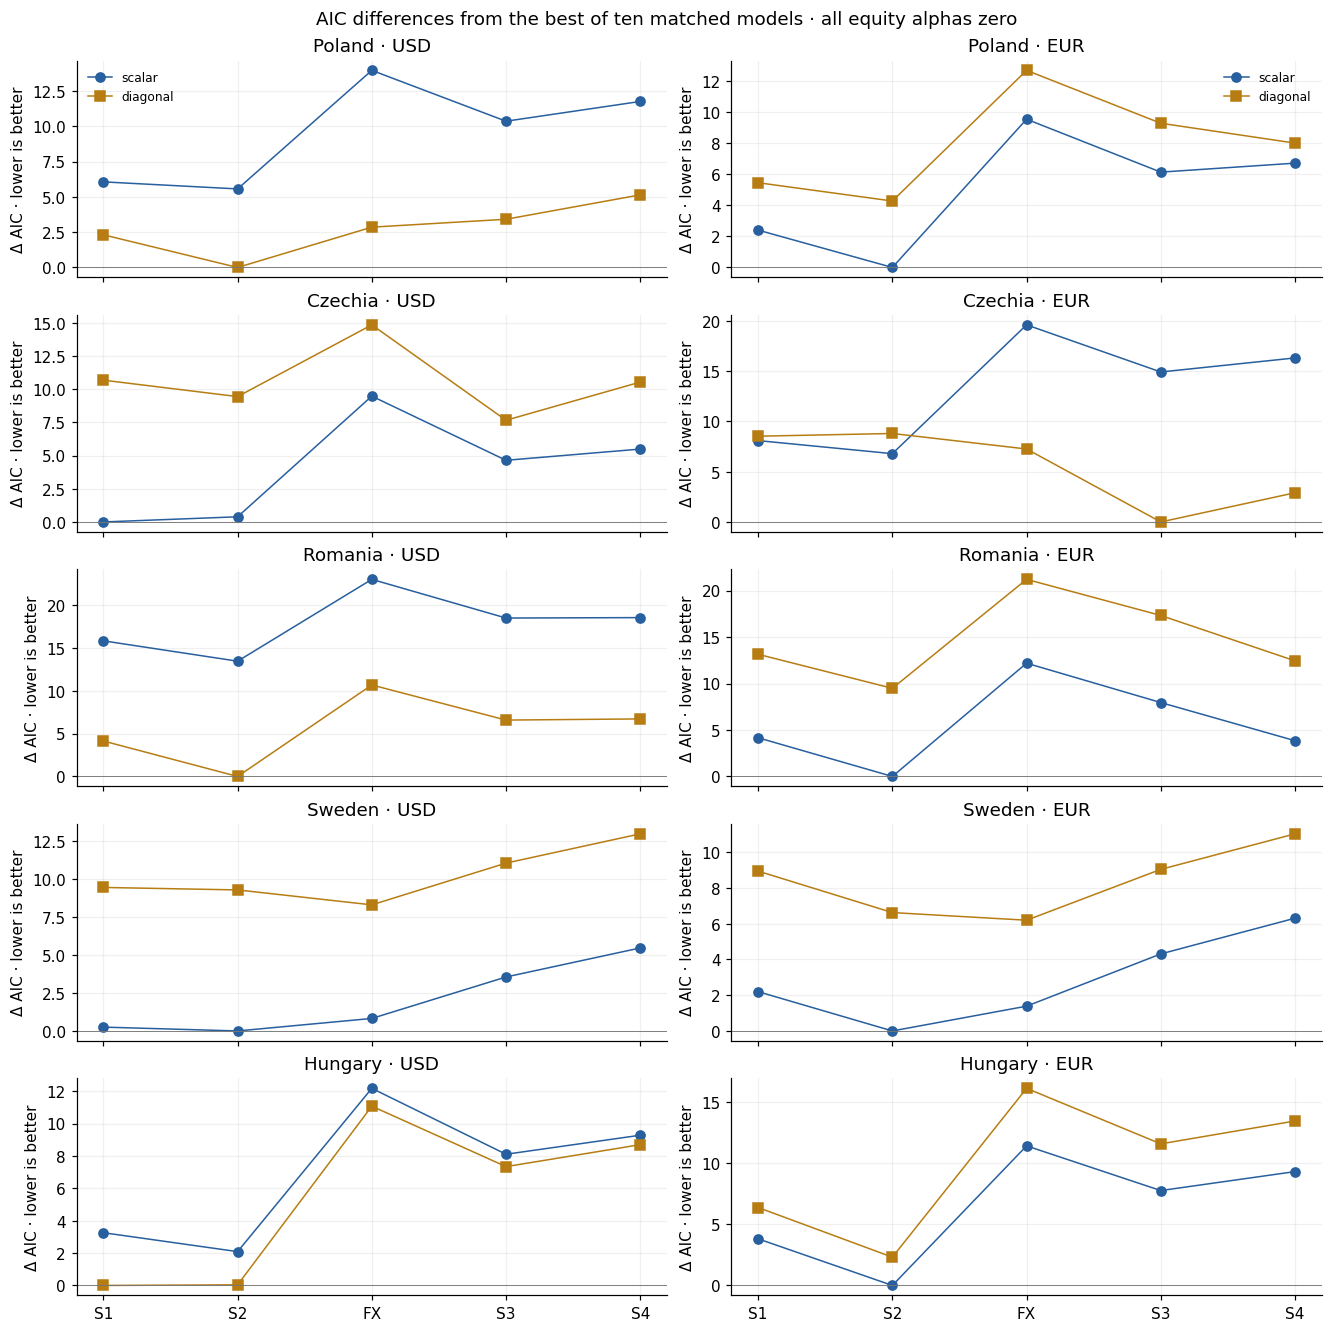

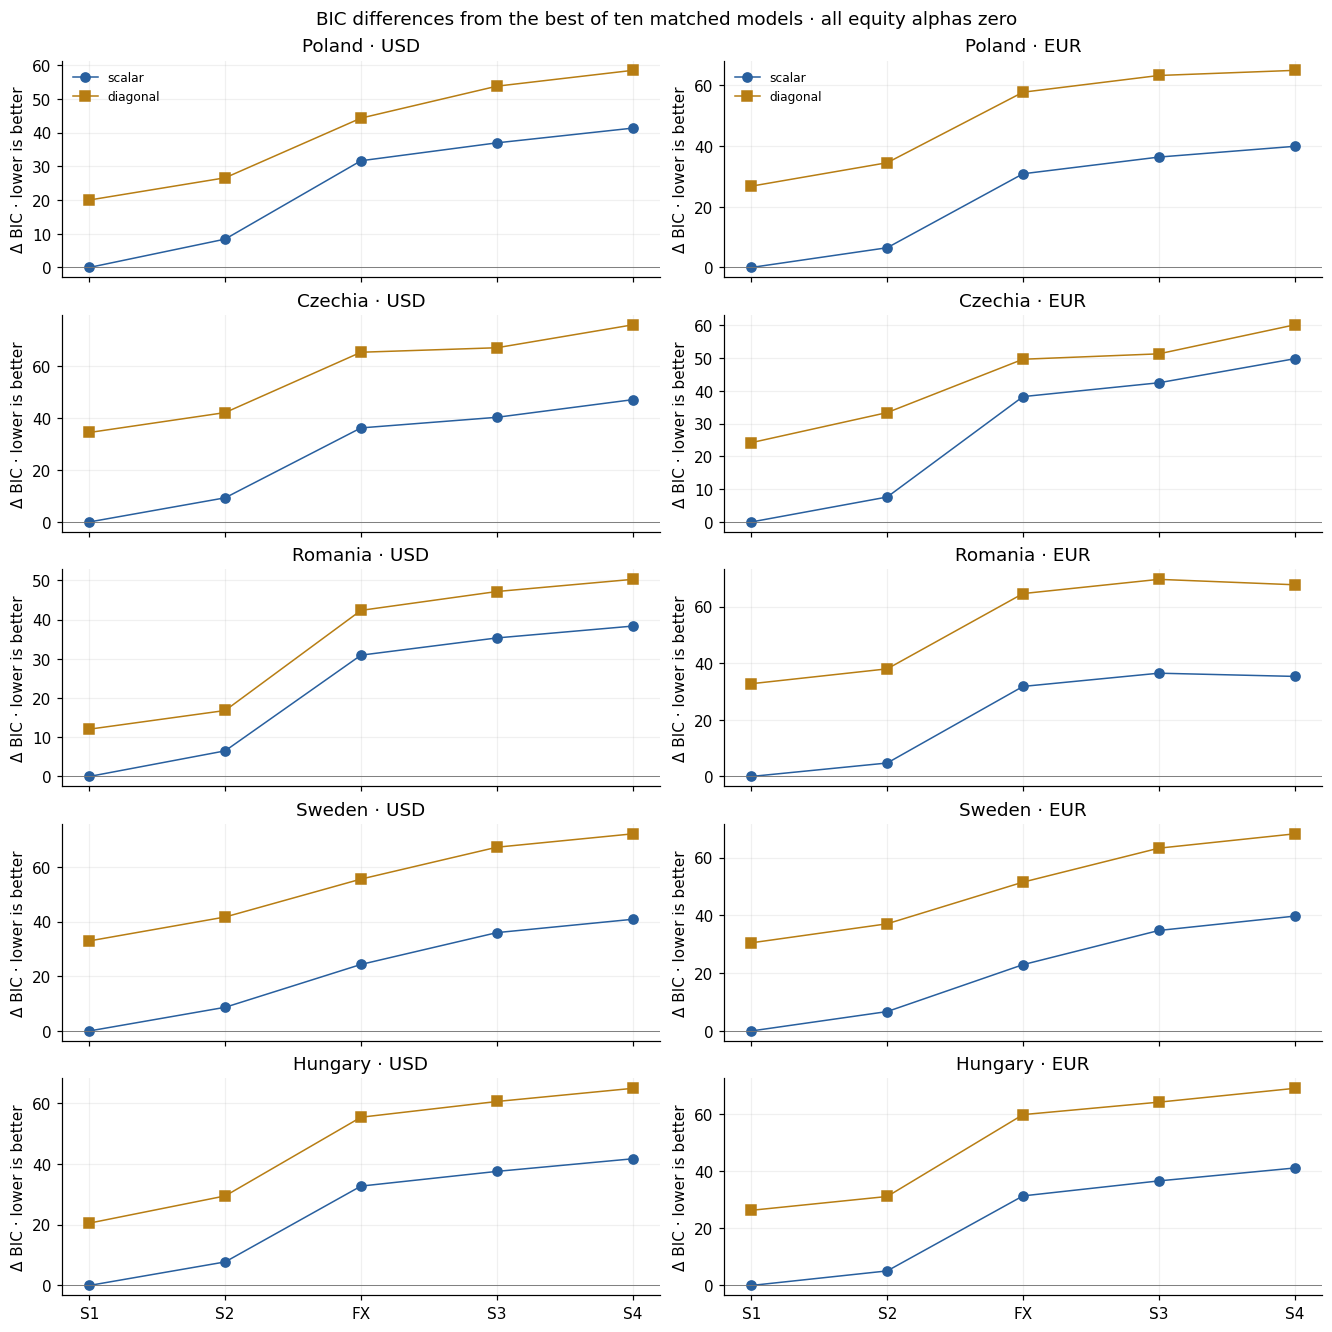

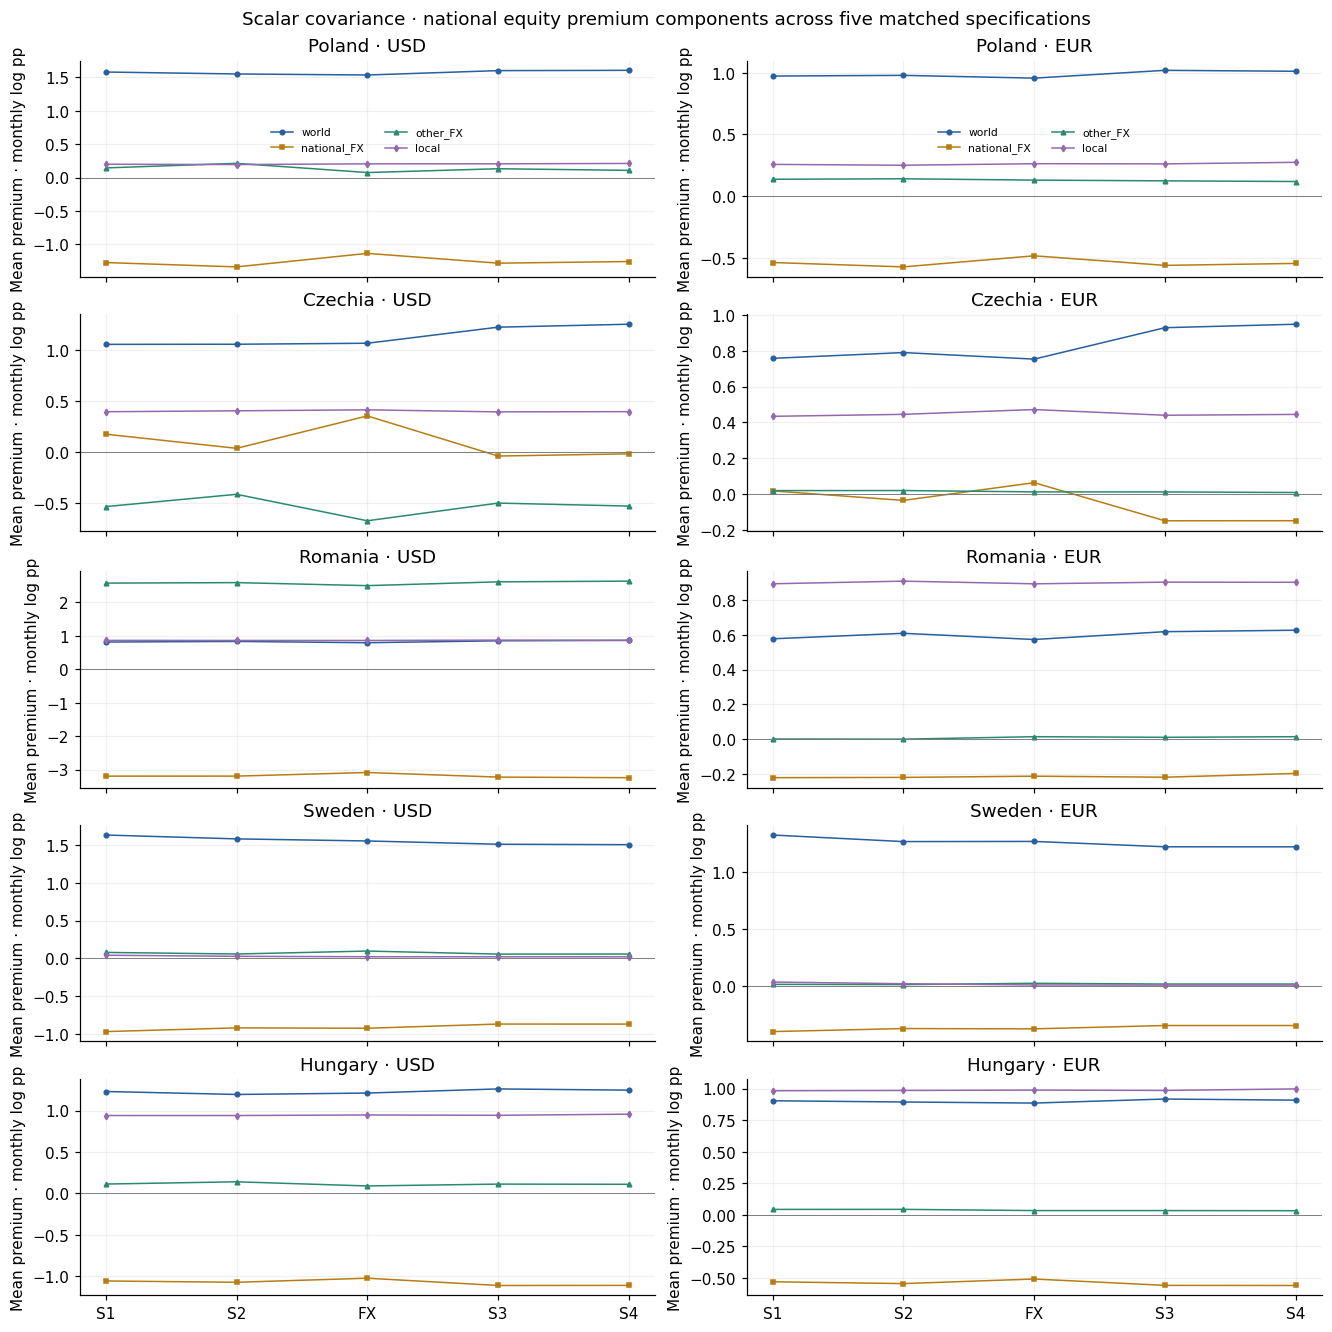

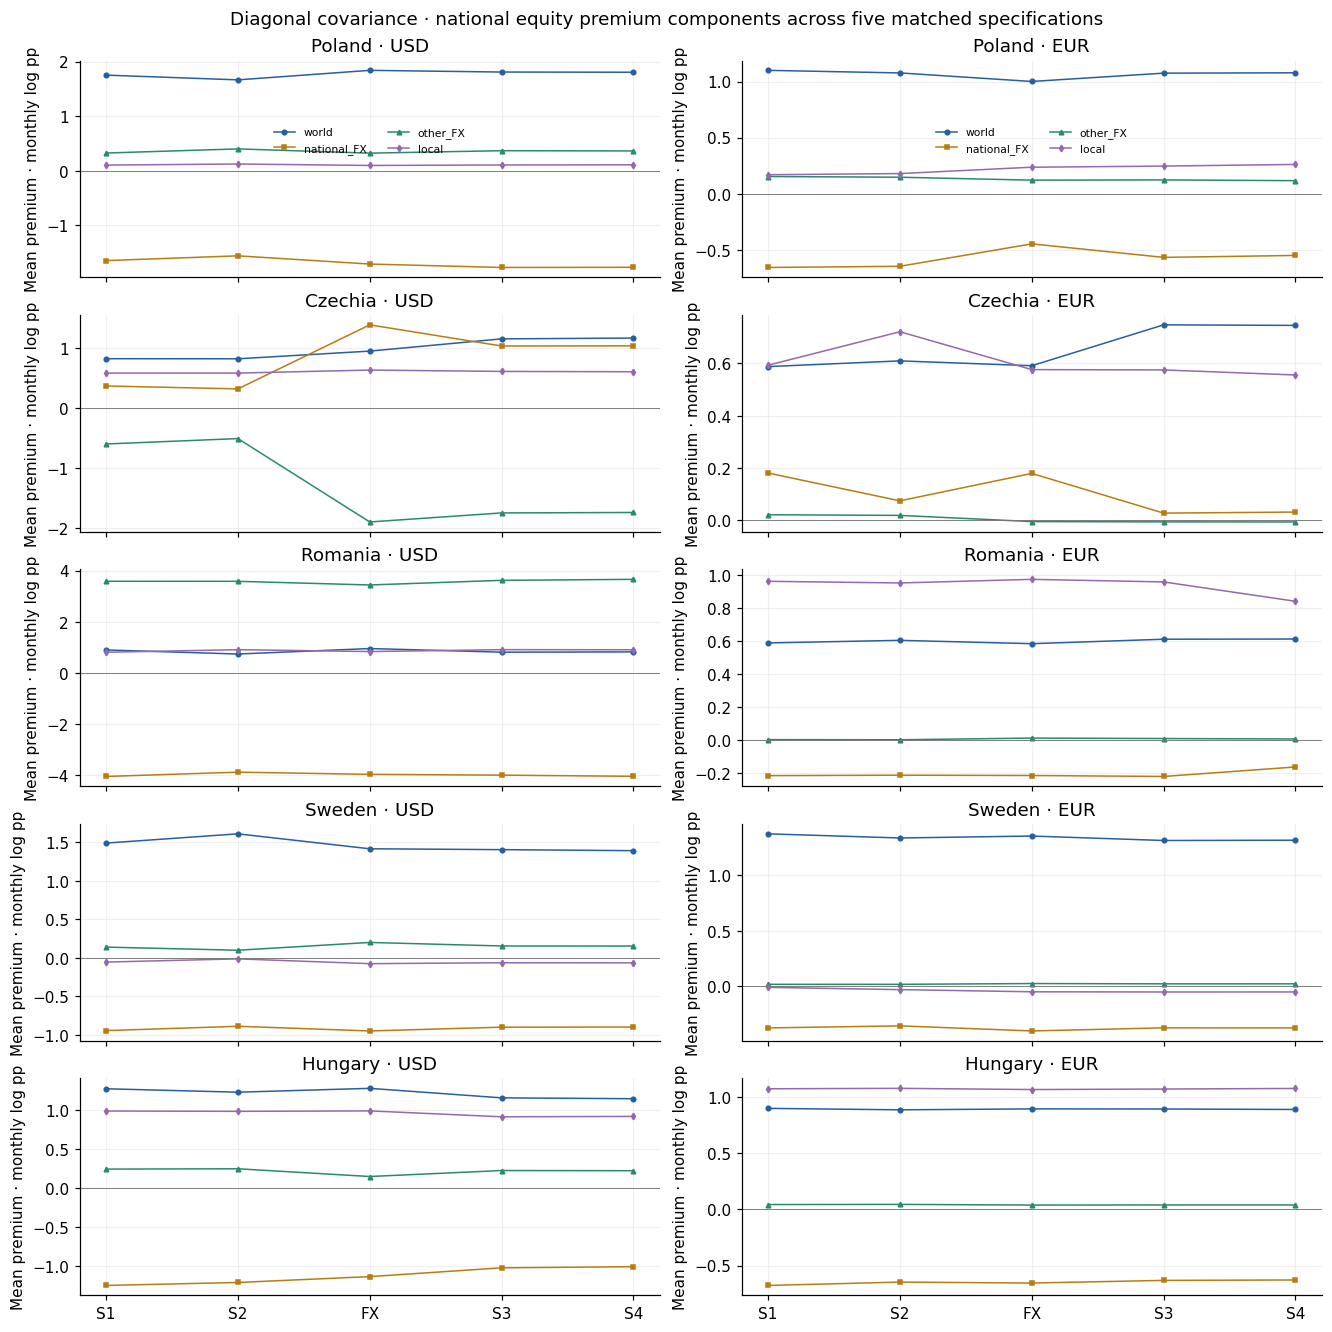

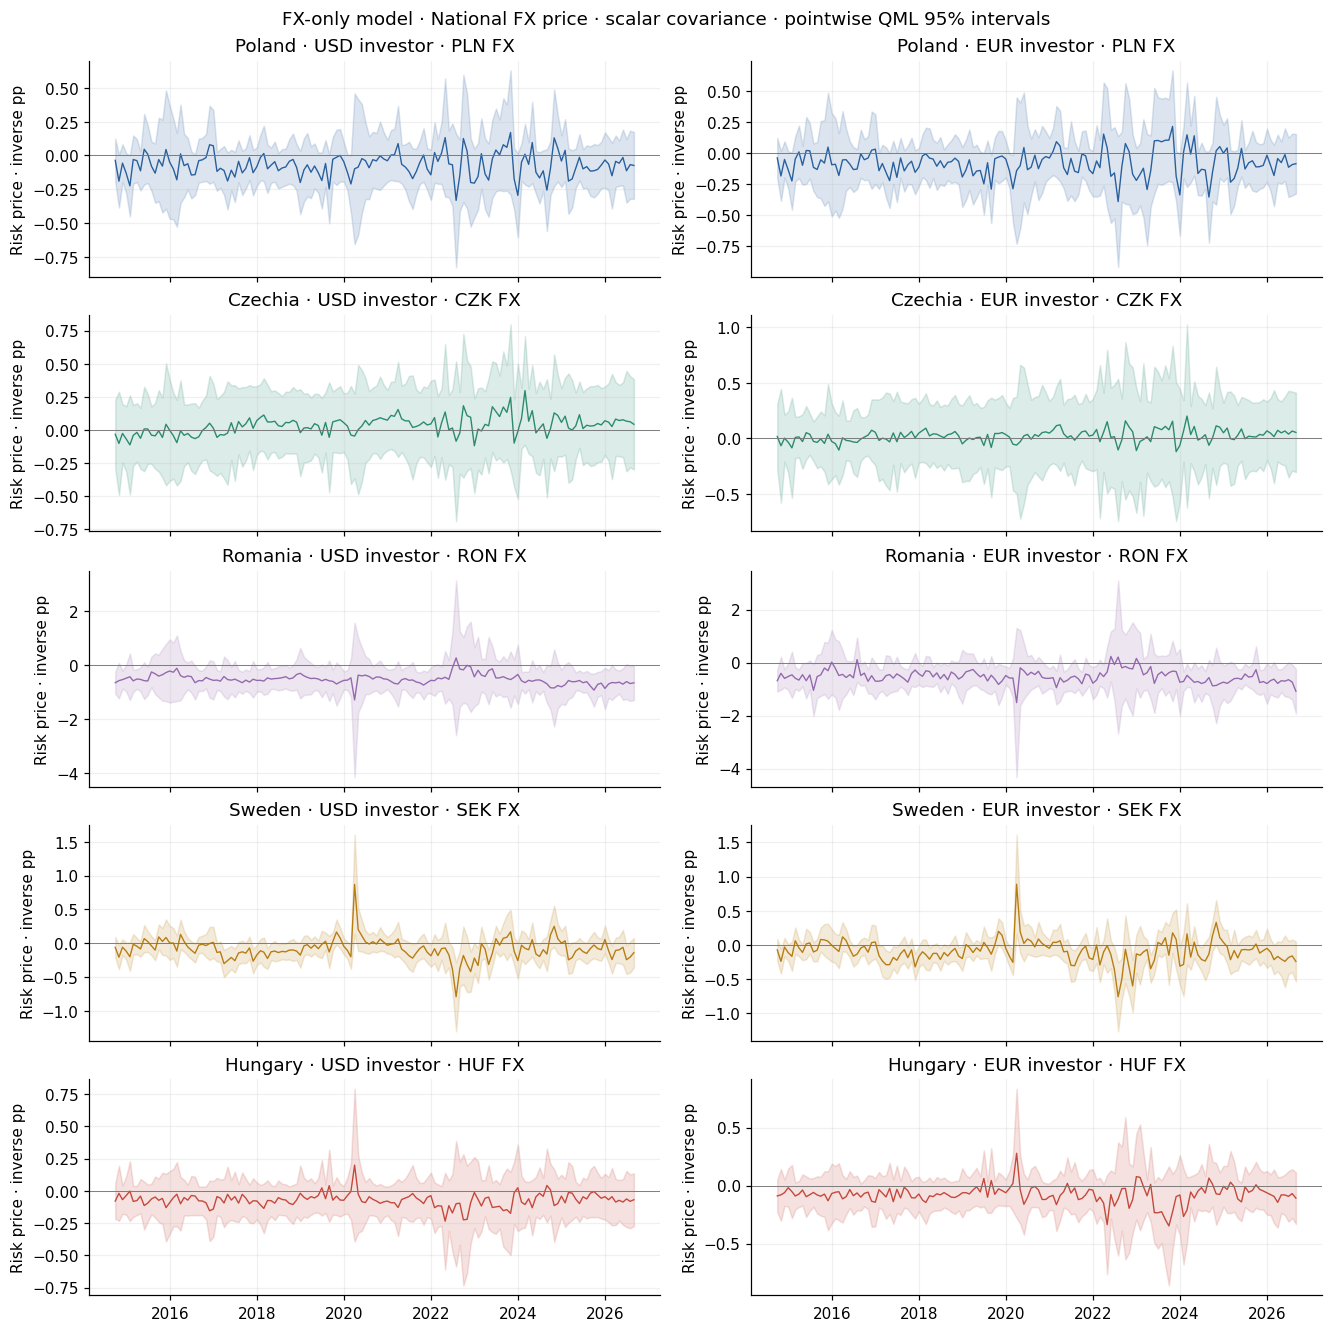

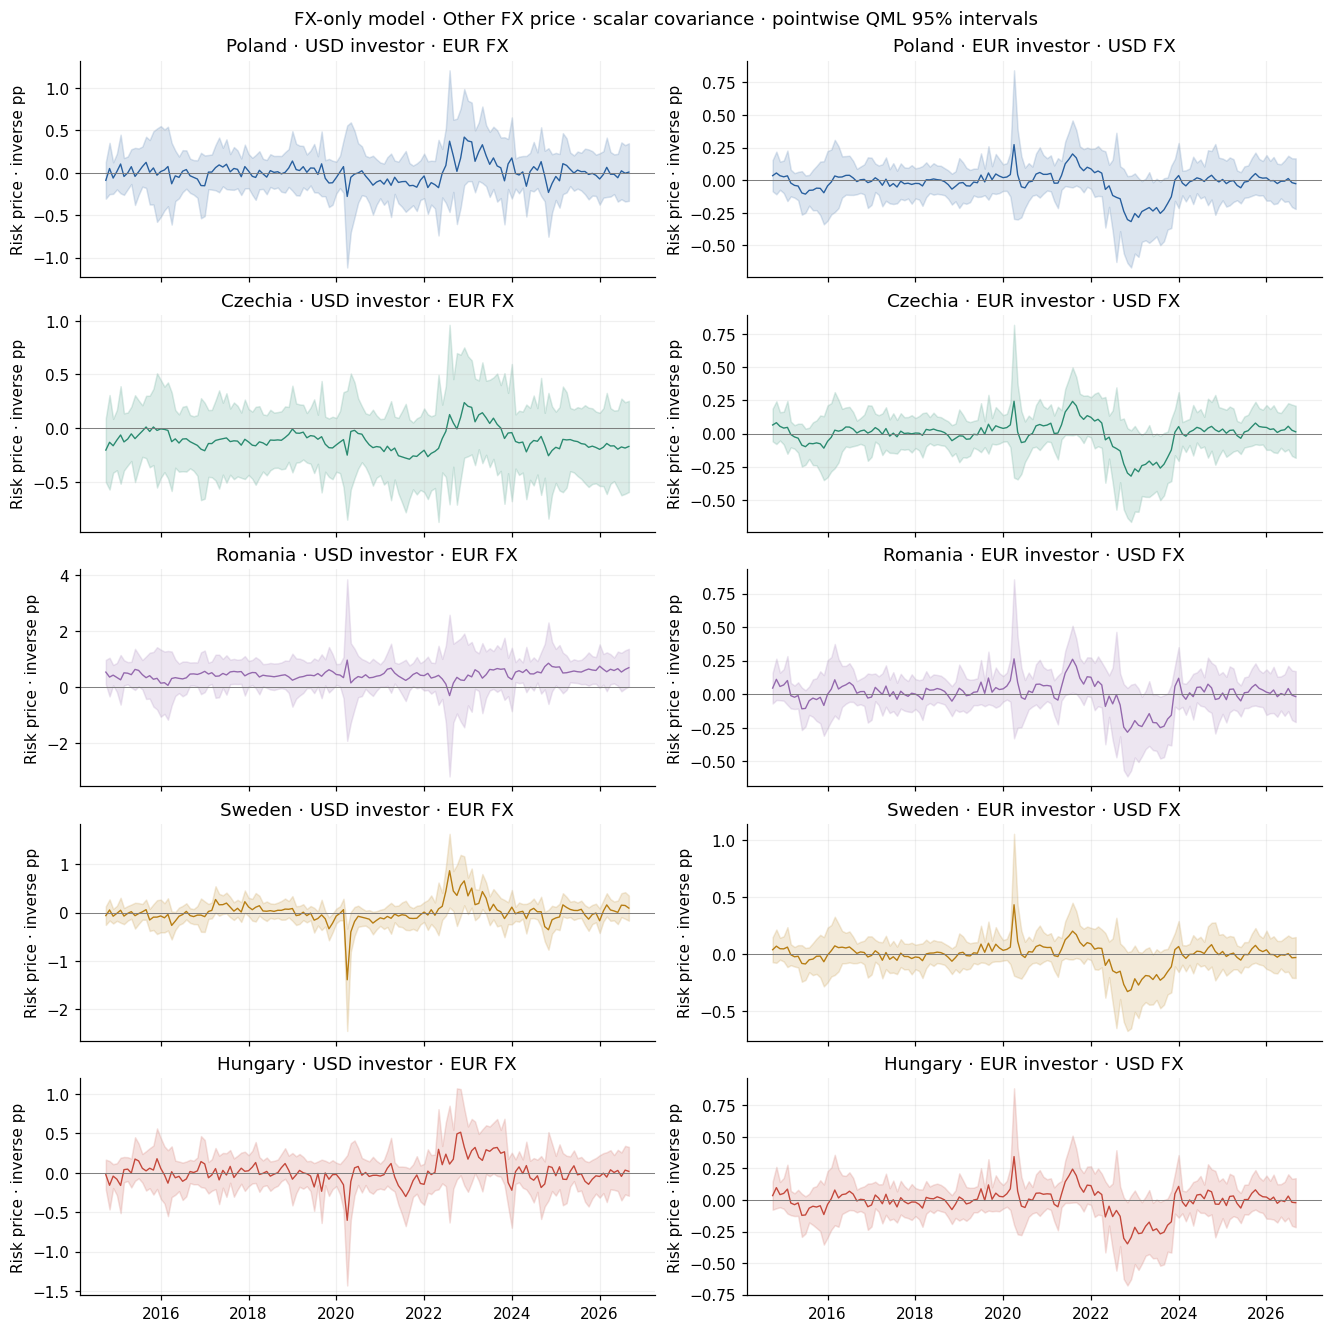

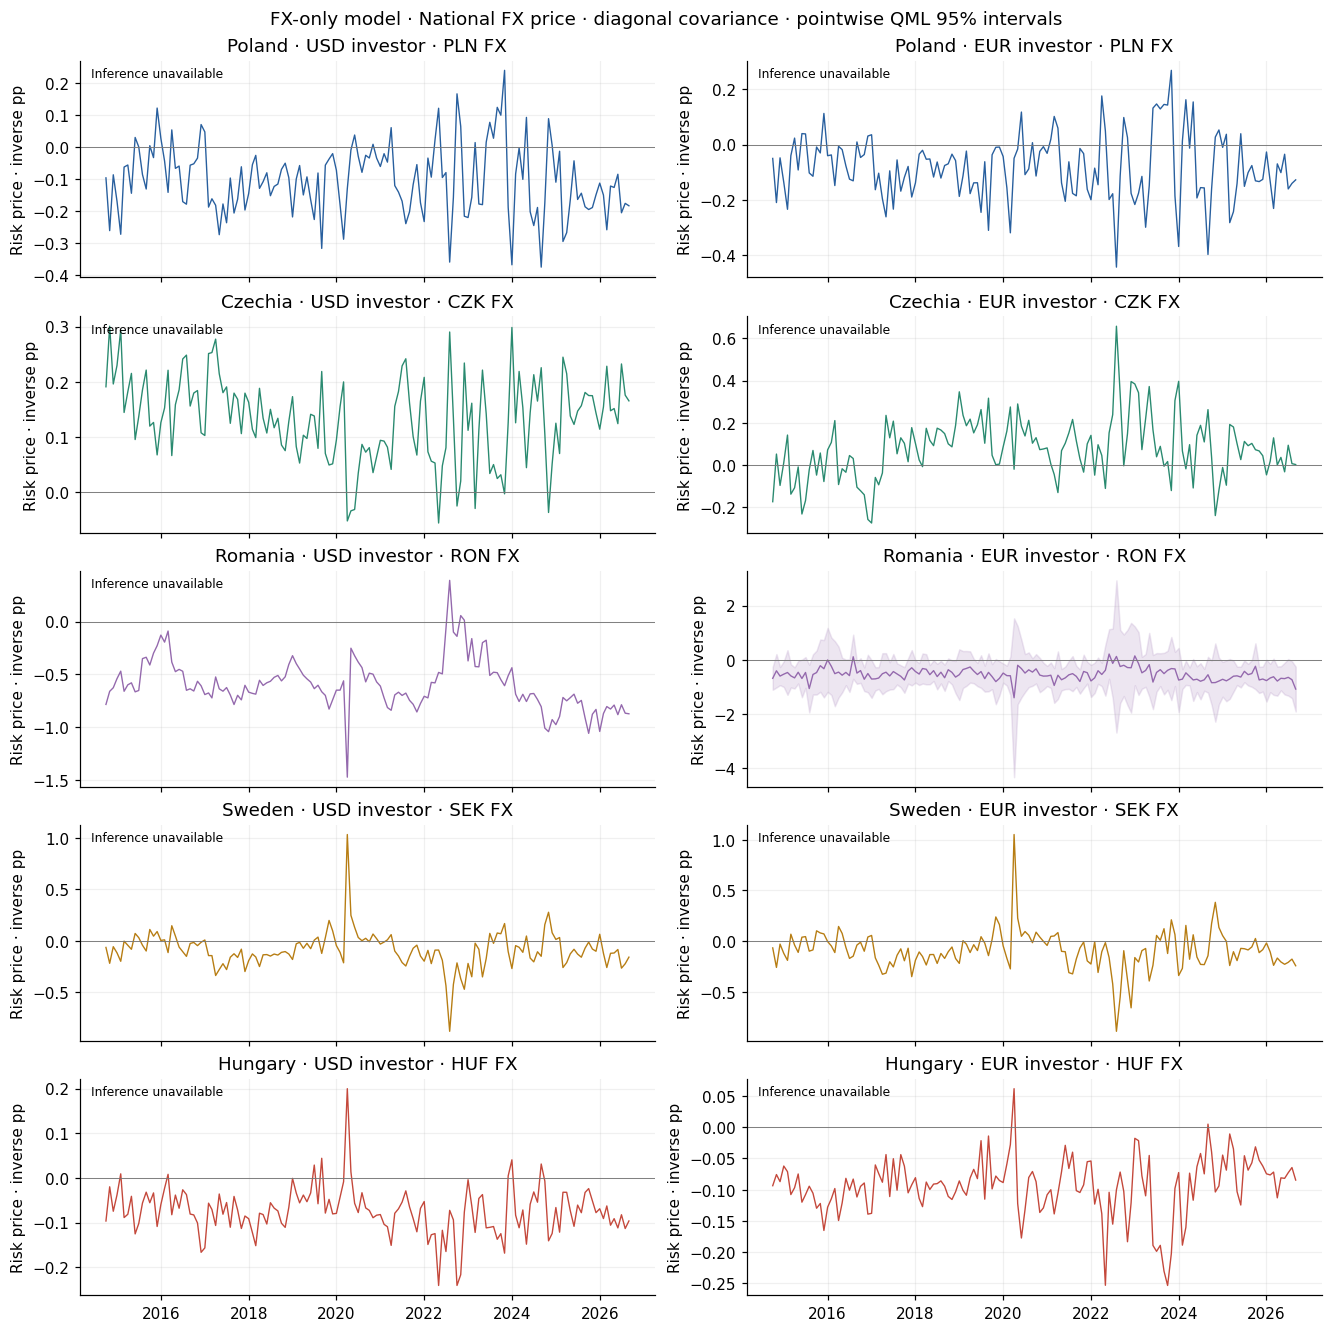

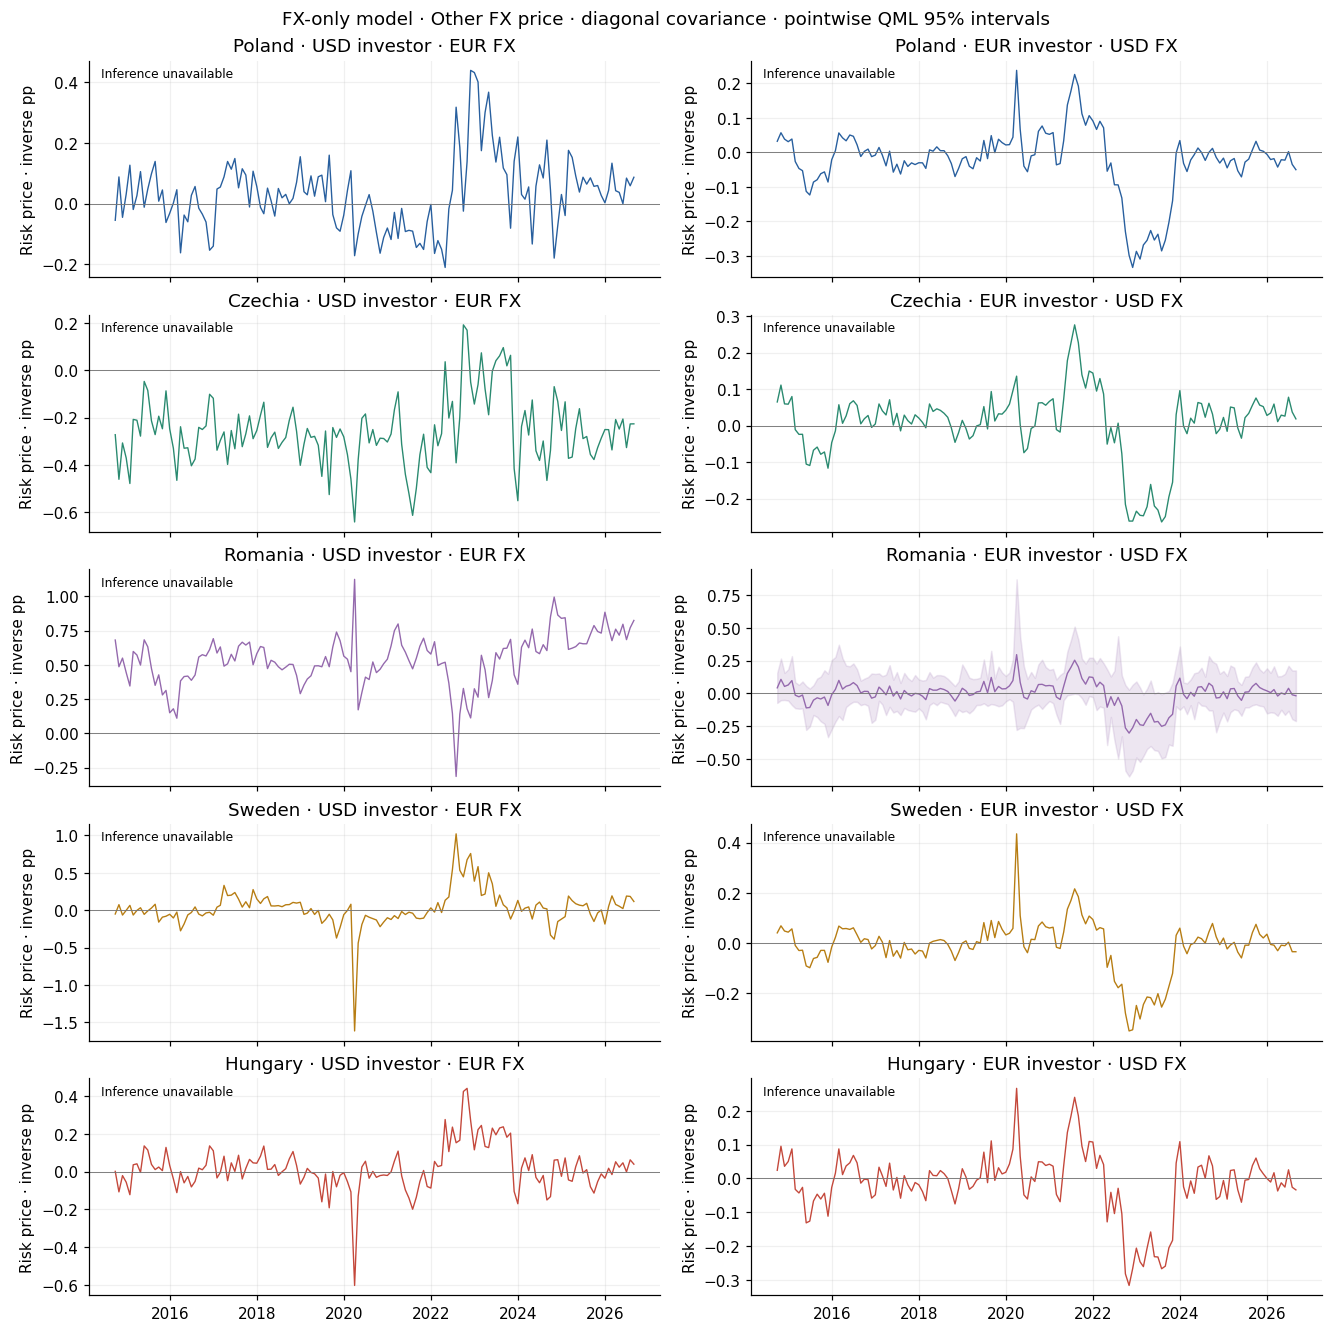

In [8]:
premium_rows, product_rows = [], []
for key, fit in fits.items():
    country, currency, covariance, stage = key; f = fit["filter"]
    prices = {"world": f["world_prices"], "national_FX": f["fx_prices"][:, 0], "other_FX": f["fx_prices"][:, 1], "local": f["local_prices"]}
    covs = {"world": f["H"][:, 2, 0], "national_FX": f["H"][:, 2, 3], "other_FX": f["H"][:, 2, 4], "local": f["H"][:, 2, 2]}
    components = {a: prices[a]*covs[a] for a in prices}; total = sum(components.values())
    np.testing.assert_allclose(total, f["mu"][:, 2], atol=1e-11, rtol=0)
    tags = {"country": country, "perspective": currency, "covariance": covariance, "stage": stage}
    for a, j in [("world", 0), ("national_FX", 3), ("other_FX", 4), ("local", 2)]:
        np.testing.assert_allclose(prices[a].mean(), engine.PRICE_SCALE*fit["theta"][j], atol=1e-12, rtol=0)
        product_rows.append({**tags, "component": a, "mean_risk_price": prices[a].mean(), "mean_covariance_pp2": covs[a].mean(),
            "mean_contribution_pp": components[a].mean(), "product_of_means_pp": prices[a].mean()*covs[a].mean(),
            "price_covariance_interaction_pp": components[a].mean()-prices[a].mean()*covs[a].mean()})
    premium_rows.extend({**tags, "month": str(month), **{a+"_price": v[t] for a, v in prices.items()},
        **{a+"_covariance_pp2": v[t] for a, v in covs.items()}, **{a+"_premium_pp": v[t] for a, v in components.items()},
        "fitted_mean_pp": total[t], "equity_alpha_pp": 0.} for t, month in enumerate(months))
premiums, product_summary = pd.DataFrame(premium_rows), pd.DataFrame(product_rows)
for criterion in ["AIC", "BIC"]:
    fig, axes = plt.subplots(5, 2, figsize=(12, 12), sharex=True, layout="constrained")
    for row, country in enumerate(NAMES):
        for col, currency in enumerate(CURRENCIES):
            ax = axes[row, col]
            for covariance, marker, color in [("scalar", "o", "#285f9e"), ("diagonal", "s", "#b77d13")]:
                g = comparison.query("country == @country and perspective == @currency and covariance == @covariance").assign(model_order=lambda x: x.stage.map({s: i for i, s in enumerate(STAGES)})).sort_values("model_order")
                ax.plot(g.model_order, g["delta_"+criterion+"_best"], marker=marker, color=color, lw=1, label=covariance)
            ax.axhline(0, color="#777777", lw=.6); ax.set(title=f"{NAMES[country]} · {currency}", ylabel=f"Δ {criterion} · lower is better", xticks=range(5), xticklabels=[MODEL_LABEL[s] for s in STAGES])
            if row == 0: ax.legend(frameon=False, fontsize=8)
    fig.suptitle(f"{criterion} differences from the best of ten matched models · all equity alphas zero")
    save_plot(f"01_{criterion}_comparison.png")
for covariance in COVARIANCES:
    fig, axes = plt.subplots(5, 2, figsize=(12, 12), sharex=True, layout="constrained")
    for row, country in enumerate(NAMES):
        for col, currency in enumerate(CURRENCIES):
            ax = axes[row, col]
            for component, marker, color in [("world", "o", "#285f9e"), ("national_FX", "s", "#b77d13"), ("other_FX", "^", "#2a8a70"), ("local", "d", "#9469ad")]:
                g = product_summary.query("country == @country and perspective == @currency and covariance == @covariance and component == @component").assign(model_order=lambda x: x.stage.map({s: i for i, s in enumerate(STAGES)})).sort_values("model_order")
                ax.plot(g.model_order, g.mean_contribution_pp, marker=marker, ms=3, color=color, lw=1, label=component)
            ax.axhline(0, color="#777777", lw=.6); ax.set(title=f"{NAMES[country]} · {currency}", ylabel="Mean premium · monthly log pp", xticks=range(5), xticklabels=[MODEL_LABEL[s] for s in STAGES])
            if row == 0: ax.legend(frameon=False, fontsize=7, ncol=2, loc="center", bbox_to_anchor=(.5, .63))
    fig.suptitle(f"{covariance.capitalize()} covariance · national equity premium components across five matched specifications")
    save_plot(f"02_premium_components_{covariance}.png")
for covariance in COVARIANCES:
    for risk, filename in [("National FX", "national"), ("Other FX", "other")]:
        fig, axes = plt.subplots(5, 2, figsize=(12, 12), sharex=True, layout="constrained")
        for row, country in enumerate(NAMES):
            for col, currency in enumerate(CURRENCIES):
                ax = axes[row, col]
                g = price_paths.query("country == @country and perspective == @currency and covariance == @covariance and stage == 5 and HAC_lag == 0 and risk == @risk")
                x = months.to_timestamp()
                ax.plot(x, g.risk_price.to_numpy(), color=COLORS[country], lw=.9)
                if g.inference_ready.all(): ax.fill_between(x, g.ci95_low.to_numpy(), g.ci95_high.to_numpy(), color=COLORS[country], alpha=.16)
                else: ax.text(.02, .97, "Inference unavailable", transform=ax.transAxes, va="top", fontsize=8)
                ax.axhline(0, color="#777777", lw=.6)
                factor = LOCAL_CURRENCIES[country] if risk == "National FX" else ("EUR" if currency == "USD" else "USD")
                ax.set(title=f"{NAMES[country]} · {currency} investor · {factor} FX", ylabel="Risk price · inverse pp")
        fig.suptitle(f"FX-only model · {risk} price · {covariance} covariance · pointwise QML 95% intervals")
        save_plot(f"03_FX_price_{filename}_{covariance}.png")

## 8. Summary and reproducibility

Read the FX constancy and zero-function tests alongside inference availability and adequacy screens.
World/local constancy is imposed in FX; its three-world-slope restriction is tested in S3. Information
criteria compare a fixed candidate set, not economic causality or hedging policy. Snapshot vintages,
public index/ETF proxies, persistent conditioners, crisis influence and a 144-month sample still
qualify interpretation. Targeted FX robustness and covariance-targeting sensitivity remain separate
extensions; notebook 29 does not claim those regional checks have already been completed.

In [9]:
fx_summary = comparison.query("stage == 5").copy()
for restriction, column, stage in [("Both FX prices constant", "FX_constancy_p_QML", 5), ("FX prices jointly zero", "FX_zero_function_p_QML", 5), ("World price constant", "world_constancy_in_S3_p_QML", 3)]:
    p = tests.query("stage == @stage and HAC_lag == 0 and restriction == @restriction")[["country", "perspective", "covariance", "p_value"]].rename(columns={"p_value": column})
    fx_summary = fx_summary.merge(p, on=["country", "perspective", "covariance"], validate="one_to_one")
for component in ["world", "national_FX", "other_FX", "local"]:
    p = product_summary.query("stage == 5 and component == @component")[["country", "perspective", "covariance", "mean_contribution_pp"]].rename(columns={"mean_contribution_pp": component+"_premium_pp"})
    fx_summary = fx_summary.merge(p, on=["country", "perspective", "covariance"], validate="one_to_one")
display(winners.set_index(["name", "perspective", "criterion"]).round(5))
display(comparison.set_index(["country", "perspective", "covariance", "stage"])[["parameters", "loglik", "AIC_rank_all10", "BIC_rank_all10", "delta_AIC_best", "delta_BIC_best", "inference_ready_QML"]].round(5))
tables = {"input_audit.csv": input_audit, "source_design_audit.csv": source_design_audit, "design_audit.csv": design_audit,
    "conditioning_design.csv": conditioning, "instrument_transform.csv": transform_table, "inflation_quality_flags.csv": quality_flags,
    "reference_audit.csv": reference_audit, "implementation_checks.csv": checks, "candidate_audit.csv": candidate_audit,
    "initial_start_audit.csv": initial_start_audit, "initial_starting_points.csv": initial_starting_points, "FX_summary.csv": fx_summary,
    "refinements.csv": refinements, "starting_points.csv": starting_points, "nesting_audit.csv": nesting_audit,
    "fit_summary.csv": fit_table, "restriction_tests.csv": tests, "price_coefficients.csv": price_coefficients,
    "inference_audit.csv": inference_audit, "parameter_bounds.csv": parameter_bounds, "risk_price_paths.csv": price_paths,
    "residual_diagnostics.csv": residuals, "cross_covariance_diagnostics.csv": cross, "diagnostic_summary.csv": diagnostic_summary,
    "model_comparison.csv": comparison, "criterion_winners.csv": winners, "premium_components.csv": premiums,
    "price_covariance_products.csv": product_summary}
for name, frame in tables.items(): frame.to_csv(OUT/name, index=False, float_format="%.17g", lineterminator=chr(10))
parameter_files = []
for key, fit in fits.items():
    case = cases[key]; f = fit["filter"]; name = f"parameters_{case['id']}.npz"
    np.savez(OUT/name, theta=fit["theta"], H=f["H"], mu=f["mu"], errors=f["errors"], scores=f["scores"],
        equity_alphas=np.zeros(3), target=f["target"], intercept=f["intercept"], Hessian=fit["inference"]["Hessian"],
        **{f"covariance_HAC{h}": e["covariance"] for h, e in fit["inference"]["estimates"].items()})
    parameter_files.append(name)
_, after = verify_inputs()
assert input_hashes == after and engine_hashes == {n: sha((ROOT/n).read_bytes()) for n in engine_hashes}
outputs = [*tables, *figure_files, *parameter_files, *initial_files, *refinement_files]
metadata = {"notebook": "29_regional_time_varying_FX_only.ipynb", "model_version": MODEL_VERSION, "engines": engine_hashes,
    "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA, "first": str(months[0]), "last": str(months[-1]), "observations_per_fit": len(months),
    "verified_fits": 80, "new_FX_fits": 20, "comparison_cases": len(fits), "refined_cases": int(sum(f["refinement_rounds"] > 0 for f in fits.values())),
    "refinement_events": len(refinements), "final_audit_sweep": sweep, "input_locks": LOCK_HASHES, "input_file_hashes": input_hashes,
    "spec": spec, "source_locations": {"notebook28": PREVIOUS.relative_to(ROOT).as_posix(), "master_designs": MASTER.relative_to(ROOT).as_posix()},
    "model_labels": MODEL_LABEL, "nested_edges": EDGES,
    "settings": {"START_DYNAMICS": START_DYNAMICS, "MAX_ITER": MAX_ITER, "MAX_ITER_OVERRIDES": {"/".join(map(str,k)): v for k,v in MAX_ITER_OVERRIDES.items()},
        "MAX_AUDIT_SWEEPS": MAX_AUDIT_SWEEPS, "CANDIDATE_TOL": CANDIDATE_TOL, "TEST_LAGS": TEST_LAGS, "HAC_LAGS": HAC_LAGS},
    "python": sys.executable, "python_version": platform.python_version(), "packages": versions,
    "outputs": {name: sha((OUT/name).read_bytes()) for name in outputs},
    "notes": ["Four pricing stages plus FX-only branch, scalar/diagonal BEKK, five countries, USD/EUR; common frozen 144 months",
        "Corrected priced FX means and structurally zero equity alphas in all 100 cases; US local price constant",
        "References verified, all tested feasible mappings audited, only demonstrated improvements refined in this output folder",
        "Existing free positive covariance intercept and stationary innovation initialization retained",
        "Full joint QML/HAC 0/3/6/12; invalid inference suppressed; pricing tests exploratory/unadjusted",
        "AIC/BIC ranks within country/investor over all ten candidates; numerical and residual flags retained",
        "Means of monthly price-covariance products; no alpha or hedging-cost component"]}
(OUT/"estimation_manifest.json").write_text(json.dumps(metadata, indent=2, sort_keys=True)+chr(10))
display(winners.groupby(["criterion", "stage", "covariance"]).size().rename("country/investor winners"))
display(fx_summary.set_index(["country", "perspective", "covariance"])[["parameters", "AIC_rank_all10", "BIC_rank_all10", "inference_ready_QML", "FX_constancy_p_QML", "FX_zero_function_p_QML", "world_constancy_in_S3_p_QML", "national_FX_premium_pp"]].round(5))
display(Markdown(f"**FX-only evidence:** primary QML inference is available for **{int(fx_summary.inference_ready_QML.sum())}/20** fits. "
    f"The FX branch wins **{int(winners.query('criterion == \"AIC\"').stage.eq(5).sum())}/10 AIC** and "
    f"**{int(winners.query('criterion == \"BIC\"').stage.eq(5).sum())}/10 BIC** country/investor comparisons. "
    "Missing p-values reflect unavailable inference, not acceptance of constancy."))
display(Markdown(f"**Completed:** {len(fits)} aligned zero-alpha cases, 80 verified notebook-28 references and 20 new FX fits and "
    f"**{metadata['refined_cases']}** refined cases; **{months[0]}–{months[-1]} ({len(months)} months)** in base. "
    f"Saved {len(tables)} tables and {len(figure_files)} charts in `{OUT.relative_to(ROOT)}`. "
    "All frozen inputs and earlier outputs remain unchanged; criterion winners still require numerical and diagnostic qualification."))

country  stage       stage_name model  \
name    perspective criterion                                         
Hungary USD         AIC            HU      1  Constant prices    S1   
                    BIC            HU      1  Constant prices    S1   
        EUR         AIC            HU      2         TV world    S2   
                    BIC            HU      1  Constant prices    S1   
Poland  USD         AIC            PL      2         TV world    S2   
                    BIC            PL      1  Constant prices    S1   
        EUR         AIC            PL      2         TV world    S2   
                    BIC            PL      1  Constant prices    S1   
Czechia USD         AIC            CZ      1  Constant prices    S1   
                    BIC            CZ      1  Constant prices    S1   
        EUR         AIC            CZ      3    TV world + FX    S3   
                    BIC            CZ      1  Constant prices    S1   
Romania USD         AIC            RO      2         TV world    S2   
                    BIC            RO      1  Constant prices    S1   
        EUR         AIC            RO      2         TV world    S2   
                    BIC            RO      1  Constant prices    S1   
Sweden  USD         AIC            SE      2         TV world    S2   
                    BIC            SE      1  Constant prices    S1   
        EUR         AIC            SE      2         TV world    S2   
                    BIC            SE      1  Constant prices    S1   

                              covariance  criterion_value  \
name    perspective criterion                               
Hungary USD         AIC         diagonal       3200.50799   
                    BIC           scalar       3269.10297   
        EUR         AIC           scalar       3199.10030   
                    BIC           scalar       3268.25264   
Poland  USD         AIC         diagonal       3048.31840   
                    BIC           scalar       3119.71875   
        EUR         AIC           scalar       3051.31409   
                    BIC           scalar       3119.05190   
Czechia USD         AIC           scalar       2947.72174   
                    BIC           scalar       3013.05763   
        EUR         AIC         diagonal       2938.85540   
                    BIC           scalar       3012.28744   
Romania USD         AIC         diagonal       2849.84858   
                    BIC           scalar       2931.02688   
        EUR         AIC           scalar       2860.78534   
                    BIC           scalar       2930.28384   
Sweden  USD         AIC           scalar       2991.98783   
                    BIC           scalar       3057.57554   
        EUR         AIC           scalar       2989.85785   
                    BIC           scalar       3057.39126   

                               inference_ready_QML  \
name    perspective criterion                        
Hungary USD         AIC                      False   
                    BIC                       True   
        EUR         AIC                       True   
                    BIC                       True   
Poland  USD         AIC                      False   
                    BIC                       True   
        EUR         AIC                       True   
                    BIC                       True   
Czechia USD         AIC                       True   
                    BIC                       True   
        EUR         AIC                      False   
                    BIC                       True   
Romania USD         AIC                      False   
                    BIC                       True   
        EUR         AIC                       True   
                    BIC                       True   
Sweden  USD         AIC                       True   
                    BIC                       True   
        EUR         AIC                     

parameters      loglik  AIC_rank_all10  \
country perspective covariance stage                                           
HU      USD         scalar     1              22 -1579.88354               4   
                               2              25 -1576.29927               3   
                               3              33 -1571.30830               6   
                               4              34 -1570.89607               8   
                    diagonal   1              30 -1570.25400               1   
...                                          ...         ...             ...   
RO      EUR         diagonal   5              38 -1402.99819              10   
SE      USD         scalar     5              30 -1466.40472               3   
                    diagonal   5              38 -1462.13562               6   
        EUR         scalar     5              30 -1465.62216               2   
                    diagonal   5              38 -1460.02700               5   

                                      BIC_rank_all10  delta_AIC_best  \
country perspective covariance stage                                   
HU      USD         scalar     1                   1         3.25909   
                               2                   2         2.09054   
                               3                   6         8.10861   
                               4                   7         9.28415   
                    diagonal   1                   3         0.00000   
...                                              ...             ...   
RO      EUR         diagonal   5                   8        21.21103   
SE      USD         scalar     5                   3         0.82160   
                    diagonal   5                   8         8.28340   
        EUR         scalar     5                   3         1.38647   
                    diagonal   5                   8         6.19614   

                                      delta_BIC_best  inference_ready_QML  
country perspective covariance stage                                       
HU      USD         scalar     1             0.00000                 True  
                               2             7.74089                 True  
                               3            37.51747                 True  
                               4            41.66282                 True  
                    diagonal   1            20.49942                False  
...                                              ...                  ...  
RO      EUR         diagonal   5            64.56544                 True  
SE      USD         scalar     5            24.32829                 True  
                    diagonal   5            55.54860                False  
        EUR         scalar     5            22.94745                 True  
                    diagonal   5            51.51564                False  

[100 rows x 7 columns]

criterion  stage  covariance
AIC        1      diagonal       1
                  scalar         1
           2      diagonal       2
                  scalar         5
           3      diagonal       1
BIC        1      scalar        10
Name: country/investor winners, dtype: int64

parameters  AIC_rank_all10  BIC_rank_all10  \
country perspective covariance                                               
HU      USD         scalar              30              10               5   
                    diagonal            38               9               8   
        EUR         scalar              30               7               5   
                    diagonal            38              10               8   
PL      USD         scalar              30              10               5   
                    diagonal            38               3               8   
        EUR         scalar              30               9               4   
                    diagonal            38              10               8   
CZ      USD         scalar              31               7               4   
                    diagonal            39              10               8   
        EUR         scalar              31              10               5   
                    diagonal            39               4               7   
RO      USD         scalar              30              10               5   
                    diagonal            38               5               8   
        EUR         scalar              30               6               3   
                    diagonal            38              10               8   
SE      USD         scalar              30               3               3   
                    diagonal            38               6               8   
        EUR         scalar              30               2               3   
                    diagonal            38               5               8   

                                inference_ready_QML  FX_constancy_p_QML  \
country perspective covariance                                            
HU      USD         scalar                     True             0.54390   
                    diagonal                  False                 NaN   
        EUR         scalar                     True             0.37304   
                    diagonal                  False                 NaN   
PL      USD         scalar                     True             0.58456   
                    diagonal                  False                 NaN   
        EUR         scalar                     True             0.55740   
                    diagonal                  False                 NaN   
CZ      USD         scalar                     True             0.38327   
                    diagonal                  False                 NaN   
        EUR         scalar                     True             0.64798   
                    diagonal                  False                 NaN   
RO      USD         scalar                     True             0.36769   
                    diagonal                  False                 NaN   
        EUR         scalar                     True             0.40106   
                    diagonal                   True             0.40023   
SE      USD         scalar                     True             0.06800   
                    diagonal                  False                 NaN   
        EUR         scalar                     True             0.02034   
                    diagonal                  False                 NaN   

                                FX_zero_function_p_QML  \
country perspective covariance                           
HU      USD         scalar                     0.37251   
                    diagonal                       NaN   
        EUR         scalar                     0.46742   
                    diagonal                       NaN   
PL      USD         scalar                     0.20574   
                    diagonal                       NaN   
        EUR         scalar                     0.47889   
                    diagonal                       NaN   
CZ      USD         scalar                     0.37536   
                    diagon

**FX-only evidence:** primary QML inference is available for **11/20** fits. The FX branch wins **0/10 AIC** and **0/10 BIC** country/investor comparisons. Missing p-values reflect unavailable inference, not acceptance of constancy.

**Completed:** 100 aligned zero-alpha cases, 80 verified notebook-28 references and 20 new FX fits and **0** refined cases; **2014-10–2026-09 (144 months)** in base. Saved 28 tables and 8 charts in `output/29_regional_time_varying_FX_only/2014-10_2026-09/fx_only_606736e5`. All frozen inputs and earlier outputs remain unchanged; criterion winners still require numerical and diagnostic qualification.